# DM_simulation — the constrained Gadget-4 box, run through notebooks 06 and 07

**Exploratory twin of notebooks
[06](06_velocity_frame_comparison.ipynb) and [07](07_redshift_space_comparison.ipynb),
on a different simulation.** Every stage below is the *same library function* those two
notebooks call — `run_both_frames`, `normalize_comparison`, `make_comparison_figure`,
`build_tracer_spaces`, `run_both_spaces`, `make_redshift_comparison_figure` — with no
estimator forked and no pipeline logic reimplemented here (CLAUDE.md: one library, two thin
consumers). The **only** thing that changes is the loader.

That is possible because both pipelines take `observer` and `n_bar` as explicit arguments at
every stage. The one place either of them reaches for MDPL2 is its loader, so
`dvcorr.pipeline.dm_snapshot` supplies two replacements —
`load_and_carve_particles` and `load_and_carve_particles_buffered` — and everything
downstream is called verbatim. Read that module's docstring first; it is the authority on
what differs and why nothing in `dvcorr.conventions` had to be edited to get here.

## What this simulation is

`data/DM_simulation.hdf5` is a Gadget-4 snapshot at z = 0: 256³ dark-matter particles in a
**300 h⁻¹ Mpc** periodic box, Ωm = 0.308, h = 0.678. Its initial-conditions filename
(`IC_const_gadget4_2mrs_ichain0_L300.0`) identifies it as a **constrained realization built
from 2MRS** — one sample from a reconstruction chain — so unlike MDPL2 it is a mock of *our
actual* local volume rather than a statistically equivalent random box, and the box centre is
intended to be **us**. That provenance is read off a filename, not stated by the file; it is
worth confirming before anything leans on it.

## Three things that are different from 06/07, and change how the plots read

**1 — b = 1.** The tracer field *is* the matter field. There is no halo bias between the
density and the velocity, which is the reason to run this box at all: every MDPL2
measurement in this project is of biased tracers, and this one is not. The dipole measured
here is the matter–velocity dipole, and it is the natural calibration target for
[09](09_galaxy_bias.ipynb).

**2 — the centres are particles, not halos.** A centre drawn from this field is a random
*particle*, so the centre population samples the matter field **by mass**, and its velocity is
its halo's bulk flow **plus its own virial velocity**. The virial part is uncorrelated with
the surrounding large-scale density: it tilts the axis away from the flow (diluting the
dipole) while raising the |v| weight of centres in dense regions. Both act the same way in
every shell, so they rescale the amplitude rather than bend it. Do **not** read a smaller
ζ̂₁ here than in 06 as a statement about the density field.

**3 — the box is 3.3× smaller in each dimension.** `MAX_ANALYSIS_RADIUS` is 150 h⁻¹ Mpc
here, not 500, and the analysis geometry has to fit inside it *twice over* for the
redshift-space half (carve, then buffer). That is what forces some of the parameters below away from
06/07's — the shell ladder is not one of them; see "Parameters".

## Sign

Unchanged, and still the gate. Both frames are **positive** for coherent infall: mass flows
toward overdensities, so the density excess lies ahead of the flow (velocity frame), and
ζ_ℓ = (−1)^ℓ ξ_Tu,ℓ flips hard rule 2's negative group-centred ξ_Tu,1 into a positive ζ₁
(observer frame). A negative dipole from either frame **on a resolved shell** is an
orientation bug, not a result. The qualifier matters here in a way it did not in 06: the
innermost bin sits below this box's resolution floor, and §B shows a genuine, physical sign
flip in redshift space that is neither.

In [1]:
%matplotlib inline

import numpy as np

from dvcorr.config import PathsConfig, ShellConfig, SPACING_LOG
from dvcorr.estimators.shell_dipole import expected_shell_occupancy
from dvcorr.pipeline.dm_snapshot import (
    read_snapshot_header,
    snapshot_observer,
    snapshot_number_density,
    load_and_carve_particles,
    load_and_carve_particles_buffered,
    DEFAULT_SUBSAMPLE_FACTOR,
)
from dvcorr.pipeline.velocity_centered import draw_candidates_from_arrays, select_shared_centers
from dvcorr.pipeline.velocity_frame_comparison import (
    ComparisonRunConfig,
    run_both_frames,
    normalize_comparison,
    make_comparison_figure,
    make_angle_diagnostic_figure,
)
from dvcorr.pipeline.redshift_space_comparison import (
    RedshiftSpaceRunConfig,
    build_tracer_spaces,
    select_redshift_shared_centers,
    real_space_center_set,
    run_both_spaces,
    normalize_redshift_comparison,
    membership_diagnostics,
    make_redshift_comparison_figure,
    make_single_center_figure,
)

paths = PathsConfig()
print("snapshot:", paths.dm_snapshot)

snapshot: /home/ofeke2000/Cross-correlating-Tempel-SDSS-groups-with-Cosmicflows-4-peculiar-velocities/data/DM_simulation.hdf5


## The box, read from its own header

`read_snapshot_header` reads the `Header` and `Parameters` attribute groups and nothing else
— no particle data is touched, so this is instant and can be done before deciding whether the
run's radii even fit. Nothing below is typed in by hand: a hand-copied box size or particle
mass is a silent multiplicative factor on every normalized amplitude, and the file states
both. The loader also **checks the code units** against Gadget's own `Parameters` rather than
assuming them, because a snapshot written in kpc/h would load without error and produce a
plausible-looking curve at the wrong scale.

`snapshot_observer` is this box's counterpart to `conventions.OBSERVER_POSITION` — same
convention (one observer per run, at the box centre), different box. It is passed into the
`observer` argument every downstream stage already has; nothing is redefined locally.

In [2]:
box = read_snapshot_header(paths.dm_snapshot)
observer = snapshot_observer(box)

print(f"box_size                  : {box.box_size:.0f} h^-1 Mpc      (MDPL2: 1000)")
print(f"max_analysis_radius       : {box.max_analysis_radius:.0f} h^-1 Mpc      (MDPL2: 500)")
print(f"observer                  : {observer}   (MDPL2: [500 500 500])")
print(f"n_particles               : {box.n_particles:,}  = {round(box.n_particles ** (1/3)):d}^3")
print(f"particle_mass             : {box.particle_mass:.3e} h^-1 M_sun  (MDPL2: 1.505e+09)")
print(f"mean interparticle spacing: {box.mean_interparticle_spacing:.3f} h^-1 Mpc")
print(f"softening                 : {box.softening:.2f} h^-1 Mpc")
print(f"n_bar (full snapshot)     : {box.number_density:.4f} (h^-1 Mpc)^-3  (MDPL2 full: 0.1274)")
print()
print(f"redshift  : {box.redshift:.3e}   scale factor : {box.scale_factor:.12f}")
print(f"cosmology : Om0 = {box.omega_m}, OmL = {box.omega_lambda}, Ob0 = {box.omega_baryon}, h = {box.hubble_param}")
print(f"            (MDPL2: Om0 = 0.307115, h = 0.6777 -- this is a DIFFERENT cosmology,")
print(f"             which is why dvcorr.config.CosmologyConfig is not used on this path)")
print()
print("initial conditions:")
print(f"  {box.initial_conditions}")
print("  ^ 'IC_const_... 2mrs ...' -- a CONSTRAINED realization from 2MRS, not a random box.")

box_size                  : 300 h^-1 Mpc      (MDPL2: 1000)
max_analysis_radius       : 150 h^-1 Mpc      (MDPL2: 500)
observer                  : [150. 150. 150.]   (MDPL2: [500 500 500])
n_particles               : 16,777,216  = 256^3
particle_mass             : 1.370e+11 h^-1 M_sun  (MDPL2: 1.505e+09)
mean interparticle spacing: 1.172 h^-1 Mpc
softening                 : 0.20 h^-1 Mpc
n_bar (full snapshot)     : 0.6214 (h^-1 Mpc)^-3  (MDPL2 full: 0.1274)

redshift  : 2.220e-16   scale factor : 1.000000000000
cosmology : Om0 = 0.308, OmL = 0.692, Ob0 = 0.0482, h = 0.678
            (MDPL2: Om0 = 0.307115, h = 0.6777 -- this is a DIFFERENT cosmology,
             which is why dvcorr.config.CosmologyConfig is not used on this path)

initial conditions:
  /home/adi/gadget4/examples/2mrs_L300/IC_ichain0/IC_const_gadget4_2mrs_ichain0_L300.0_eps_last_ichain0
  ^ 'IC_const_... 2mrs ...' -- a CONSTRAINED realization from 2MRS, not a random box.


## Parameters

The shell ladder is the project default (CLAUDE.md hard rule 10): `[0, 0.5)` plus 14 log
shells of ratio √2 up to 64 h⁻¹ Mpc, the same edges as 06/07, taken from `RunConfig`'s own
default rather than retyped. Three other knobs move away from 06/07, every one of them forced
by the box or by that ladder rather than chosen for taste.

| knob | 06/07 | here | why |
|---|---|---|---|
| `sub_volume_radius` | 300 | **130** | Must clear `max_analysis_radius = 150`, and in §B the **buffered** radius `R_sub + v_margin` is the one that has to fit. 130 + 15.5 = 145.5, inside 150 with room. |
| `n_candidate_centers` | 16000 | **54000** | The core cut that binds is §B's, at margin `r_max + v_margin = 64 + 15.5`, so only centres within 130 − 79.5 = 50.5 h⁻¹ Mpc of the observer survive: ~6.6% of candidates, against MDPL2's 48%. 54000 candidates buy back ~3500 centres. |
| `v_margin_statistic` | `"max"` | **`"percentile"`** | Sets §B's buffer *and*, through the shared centre set (A.2), which centres §A sees. The fastest particle in the carve moves at ~2900 km/s, so a `"max"` margin is ~29 h⁻¹ Mpc and buffers straight through the box ceiling. See §B. |

**The resolution floor is not `min_radius`.** The ladder's innermost log edge, 0.5, sits
*below* `box.mean_interparticle_spacing` = 1.17 h⁻¹ Mpc, the scale below which this is not a
density field but a list of particles. So the config cell derives `resolved_min_radius` =
1.41, the first ladder edge at or above the spacing, and every "resolved shells" mask in this
notebook (A.7, B.6, §D) reads it. The four shells inside it, `[0, 0.5)`, `[0.5, 0.71)`,
`[0.71, 1)` and `[1, 1.41)`, are computed and plotted, as 06 shows its one-halo bins, but read
as resolution artifacts, not measurements. (Not the softening, 0.20, which is 6× finer and is
not the binding constraint for a single centre's shell; §C is where it becomes the floor.)

**What r_max = 64 costs in a 300 h⁻¹ Mpc box.** An earlier version of this notebook departed
from the default and stopped at r_max = 40 on 16000 candidates (3194 centres within 74.5 h⁻¹ Mpc).
The default ladder holds the centre count (3556) only by drawing 3.4× more candidates, the
centre sphere shrinks to 50.5 h⁻¹ Mpc, and every shell's query ball is (64/40)³ ≈ 4× larger.
§A runs on the same centre set as §B; A.2 says why, and what it costs. `subsample_factor` (below) thins the particle field: independent Bernoulli
thinning changes no correlation function, only shot noise, so ζ̂₁ is unchanged in expectation
at 1/N the runtime — and at n̄ ≈ 0.21 the thinned field is still 1.6× denser than MDPL2's
full halo catalog, so the noise it adds was already negligible.

⏱ The whole notebook, §C included, runs in ~22 minutes at these settings.


In [3]:
# The shell ladder is the project default (CLAUDE.md hard rule 10) -- RunConfig's
# own default_factory, not retyped here: [0, 0.5) + 14 log shells of ratio sqrt(2)
# up to 64 h^-1 Mpc. Shared by both halves, so the two are directly comparable.
SUB_VOLUME_RADIUS = 130.0
# r_max = 64 plus sec.B's ~15.5 h^-1 Mpc v_margin leaves a centre sphere of only
# ~50 h^-1 Mpc, ~6% of candidates (see the table above); 54000 candidates buy
# back the ~3200 centres the earlier r_max = 40 run kept from 16000.
N_CANDIDATE_CENTERS = 54_000

cfg = ComparisonRunConfig(
    sub_volume_radius=SUB_VOLUME_RADIUS,
    n_candidate_centers=N_CANDIDATE_CENTERS,
)
# sec.B's config is defined here, not in sec.B: sec.A runs on sec.B's centre set
# (A.2), and selecting that set needs this config's v_margin statistic.
rcfg = RedshiftSpaceRunConfig(
    sub_volume_radius=SUB_VOLUME_RADIUS,
    n_candidate_centers=N_CANDIDATE_CENTERS,
    shells=cfg.shells,
    v_margin_statistic="percentile",   # see the table above -- "max" overflows this box
)

# The resolution floor is no longer the ladder's own min_radius: the default
# ladder's innermost log edge (0.5) sits BELOW box.mean_interparticle_spacing.
# Take the first ladder edge at or above the spacing, so every shell outside it
# is resolved and every shell inside it is shown, not trusted.
resolved_min_radius = float(cfg.shells.shell_edges[
    np.searchsorted(cfg.shells.shell_edges, box.mean_interparticle_spacing)
])

print(cfg.shells)
print()
print("shell_edges        :", np.round(cfg.shells.shell_edges, 2))
print("sub_volume_radius  :", cfg.sub_volume_radius, "h^-1 Mpc  (ceiling", box.max_analysis_radius, ")")
print("plain core radius  :", cfg.sub_volume_radius - cfg.shells.max_radius,
      "h^-1 Mpc  (r_max only; the binding core, r_max + v_margin, is printed in A.2)")
print("n_candidate_centers:", cfg.n_candidate_centers)
print("v_margin_statistic :", rcfg.v_margin_statistic, "at percentile", rcfg.v_margin_percentile)
print("subsample_factor   :", DEFAULT_SUBSAMPLE_FACTOR,
      f"-> n_bar ~ {box.number_density / DEFAULT_SUBSAMPLE_FACTOR:.3f} (h^-1 Mpc)^-3")
print()
n_unresolved = int(np.sum(cfg.shells.shell_edges[1:] <= resolved_min_radius))
print("resolution floor   :", f"{resolved_min_radius:.3f} h^-1 Mpc, the first shell edge at or above the",
      f"{box.mean_interparticle_spacing:.2f} h^-1 Mpc interparticle spacing;")
print(f"                     the {n_unresolved} shells inside [0, {resolved_min_radius:.3f}) are shown, not trusted.")

ShellConfig(min_radius=0.5, max_radius=64.0, radii_step=10.0, sigma_star=250.0, spacing='log', n_bins=14, include_zero_bin=True)

shell_edges        : [ 0.    0.5   0.71  1.    1.41  2.    2.83  4.    5.66  8.   11.31 16.
 22.63 32.   45.25 64.  ]
sub_volume_radius  : 130.0 h^-1 Mpc  (ceiling 150.0 )
plain core radius  : 66.0 h^-1 Mpc  (r_max only; the binding core, r_max + v_margin, is printed in A.2)
n_candidate_centers: 54000
v_margin_statistic : percentile at percentile 99.9
subsample_factor   : 3 -> n_bar ~ 0.207 (h^-1 Mpc)^-3

resolution floor   : 1.414 h^-1 Mpc, the first shell edge at or above the 1.17 h^-1 Mpc interparticle spacing;
                     the 4 shells inside [0, 1.414) are shown, not trusted.


# §A — Observer frame vs. velocity frame

The notebook-06 comparison, on this box. Both frames put a velocity object at the centre of
its own shells and expand the surrounding density in multipoles; both take their **axis from
the object's motion** and weight by a **speed**. They differ in one thing only:

$$\hat z^{\,\rm obs}_\alpha = \mathrm{sign}(u_\alpha)\,\hat n_{V,\alpha},\ \ \text{weight } |u_\alpha|
\qquad\text{vs.}\qquad
\hat z^{\,\rm vel}_\alpha = \frac{\mathbf v_\alpha}{|\mathbf v_\alpha|},\ \ \text{weight } |\mathbf v_\alpha|$$

the radial projection versus the full 3-vector. Comparing them measures what is lost by
having a finite-distance observer who can only see radial velocities — and on a **particle**
field that loss is much larger than it was on halos, because a particle's velocity carries a
virial component that is isotropic with respect to the line of sight and therefore mostly
invisible in `u`. The angle diagnostic in §A.6 is where that shows up.

## A.1 — Load and carve

`load_and_carve_particles` replaces `load_and_carve`. Same contract — read a tracer
population, keep what lies within `sub_volume_radius` of the observer, widen to float64 — and
plain Euclidean distance **is** the minimum image inside the carve, because the loader has
already required `sub_volume_radius ≤ box.max_analysis_radius` (`check_run_geometry`). That
check is the piece `conventions.MAX_ANALYSIS_RADIUS` cannot supply here: the estimators test
against MDPL2's 500, which every radius in a 300 h⁻¹ Mpc box passes trivially, so without a
box-specific ceiling this run would have no effective one at all.

In [4]:
carved = load_and_carve_particles(cfg, box, paths.dm_snapshot)

print()
print(f"n_snapshot : {carved.n_snapshot:,}   (the file)")
print(f"n_total    : {carved.n_total:,}   (after the 1-in-{carved.subsample_factor} thinning -- the count n_bar uses)")
print(f"n_carved   : {carved.n_carved:,}   (inside R_sub = {cfg.sub_volume_radius:.0f})")

carved 1954394 of 5592405 particles within sub_volume_radius = 130.0 h^-1 Mpc (34.95%), subsample 1-in-3 of 16777216

n_snapshot : 16,777,216   (the file)
n_total    : 5,592,405   (after the 1-in-3 thinning -- the count n_bar uses)
n_carved   : 1,954,394   (inside R_sub = 130)


## A.2 — Candidate centres, then the SHARED centre set — §B's

Two stages, as in 06, with one deliberate difference in the second.

`draw_candidates_from_arrays` is the definition site of the seeded draw and requires `mvir`
and `is_distinct` arrays. Neither exists for particles: every particle has the same mass, and
"is this a subhalo" is not a property a particle has. They are supplied here only to satisfy
the signature — a uniform mass and an all-True flag — and **nothing downstream reads them**:
the centre selectors take their mass and distinctness arguments as optional keywords, and
they are left at `None`. The mass-funnel diagnostics (`dvcorr.pipeline.mass_diagnostics`)
must not be pointed at this pipeline; they would return a one-bar histogram.

**The centre set is §B's, not 06's.** 06 selects with `select_shared_centers` — the core cut
at `core_margin = r_max`, so a surviving centre's full shell fits inside the carve, plus the
`min_center_speed` floor — which here keeps every centre within 66 h⁻¹ Mpc of the observer.
§B cannot use that set. Its redshift-space run moves each centre by up to `v_margin` along its
line of sight, so it widens the margin to `r_max + v_margin` (centres within ~50.5) and adds a
global |v_r| cut and a through-observer guard; B.3 has the argument. Every centre §B keeps
also passes §A's cuts, and the reverse fails — so the only way to put both halves on one
population is for §A to adopt §B's set. This cell does that: `select_redshift_shared_centers`
once, and `real_space_center_set` hands its real-space half to `run_both_frames`.

**What that buys.** §D's three curves — 3D, obs, z — are measured on the same centres, and
§A's observer frame *is* §B's real space, bit for bit (checked in D.2), so no ratio in this
notebook mixes two draws. An earlier version, on an r_max = 40 ladder, ran §A on 06's selection (5514 centres) and §B on
its 3194-centre subset, and the two copies of the same curve differed by ~10% in the resolved
shells — coherently, not as noise, because the extra centres sat farther from the observer,
and in a constrained box a different sub-volume is a different answer.

**What it costs.** ~53% fewer centres than 06's selection would keep here (3556 against 7563,
a factor √(7563/3556) ≈ 1.46 on every §A error bar), and a centre sphere of 50.5 h⁻¹ Mpc
instead of 66.

Selecting this set needs `v_margin`, which only the buffered load derives, so §B's load runs
in this cell. The plain carve above stays §A's tracer field.

In [5]:
# Required by the shared draw's signature; not read by anything on this path.
# See dvcorr.pipeline.dm_snapshot's "Particles are not halos" for why they are
# not real columns.
uniform_mass = np.full(carved.n_carved, box.particle_mass)
all_distinct = np.ones(carved.n_carved, dtype=bool)

candidates = draw_candidates_from_arrays(cfg, carved.pos, carved.vel, uniform_mass, all_distinct)
print("candidate centers:", candidates.s.shape[0])
print()

# sec.B's buffered load, run here: the shared selection needs its v_margin.
buffer = load_and_carve_particles_buffered(rcfg, box, paths.dm_snapshot)
print()

rs_centers = select_redshift_shared_centers(
    rcfg, candidates.s, candidates.v, observer, buffer.v_margin_kms, buffer.v_margin_mpc
)
centers = real_space_center_set(rs_centers)

core_margin = rcfg.shells.max_radius + buffer.v_margin_mpc
print()
print("n_candidates       :", centers.n_candidates)
print("n_core             :", centers.n_core,
      f"  (core_margin = r_max + v_margin = {core_margin:.2f} -> centres within "
      f"{rcfg.sub_volume_radius - core_margin:.2f} h^-1 Mpc)")
print("n_dropped_slow     :", centers.n_dropped_slow)
print("dropped, |v_r| cut :", rs_centers.n_dropped_v_r_percentile)
print("dropped, flip guard:", rs_centers.n_dropped_flip)
print("n_centers          :", centers.n_centers, " <- used by BOTH frames here, and BOTH spaces in sec.B")
print()
# For reference only: what notebook 06's plain selection would have kept.
plain = select_shared_centers(cfg, candidates.s, candidates.v, observer)
print(f"(06's plain selection, core_margin = r_max, would keep {plain.n_centers})")

speeds = np.linalg.norm(centers.v_centers, axis=1)
print()
print(f"center speeds  : min={speeds.min():.1f}  median={np.median(speeds):.1f}  max={speeds.max():.1f} km/s")
print("   (a particle's speed, so this includes virial motion -- notably faster than a halo sample)")

candidate centers: 54000



v_margin (percentile) = 1545.8 km/s = 15.46 h^-1 Mpc; buffered carve: 2680714 particles within 145.46 h^-1 Mpc (ceiling 150), 37.2% more than the plain 130 h^-1 Mpc carve (1954394 particles)

n_candidates = 54000 -> core cut (core_margin = 79.45800268514934) -> n_core = 3566 (6.6% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 3566 (0 dropped as too slow)
redshift-space center selection: base n_centers = 3566 (core_margin = r_max + v_margin = 79.46 h^-1 Mpc) -> global |v_r| <= 1545.8 km/s cut drops 10 -> through-observer guard drops 0 -> n_centers = 3556

n_candidates       : 54000
n_core             : 3566   (core_margin = r_max + v_margin = 79.46 -> centres within 50.54 h^-1 Mpc)
n_dropped_slow     : 0
dropped, |v_r| cut : 10
dropped, flip guard: 0
n_centers          : 3556  <- used by BOTH frames here, and BOTH spaces in sec.B

n_candidates = 54000 -> core cut (core_margin = 64.0) -> n_core = 7563 (14.0% survive) -> speed floor (min_center_speed = 1.0 km/s) -> 

## A.3 — Run both frames, and all four nulls

`run_both_frames` calls the two estimators on the same arrays and builds the velocity frame's
two nulls. Every null in either frame is a **recombination of arrays the estimator already
returned** — nothing re-queries the KDTree — which is what makes 32 independent draws of each
null affordable, and why each null is reported as a mean over those draws with their spread as
its band rather than as one curve.

The velocity frame needs a **random-axis** null rather than a speed shuffle: it is fully
self-aligned (axis and scalar come from the same vector), so permuting `|v_α|` leaves every
centre's axis–density alignment intact and the positive-definite weight keeps the stack at
`N·⟨|v|⟩·⟨A⟩` — no null at all. Randomizing the axis is the guard against that. See notebook
06 for the full argument; none of it changes on this box.

In [6]:
results = run_both_frames(cfg, centers, carved.pos, observer)

obs_result, vel_result = results.obs_result, results.vel_result
print()
print("obs n_centers :", obs_result.n_centers)
print("vel n_centers :", vel_result.n_centers)

# Occupancy is pure geometry and cannot depend on the axis: a strong invariant.
print("per-center occupancy identical across frames:",
      np.array_equal(obs_result.per_center_count, vel_result.per_center_count))


obs n_centers : 3556
vel n_centers : 3556
per-center occupancy identical across frames: True


## A.4 — Normalize

`snapshot_number_density` replaces `box_number_density` — identical arithmetic (count over
box volume), against `box.box_size` instead of the frozen `conventions.BOX_SIZE = 1000`. It
is fed `carved.n_total`, the count of tracers in the **whole box after the thinning**, not
`box.n_particles`: using the full count against a thinned field would inflate n̄ by
`subsample_factor` and suppress every ζ̂₁ by that flat factor, with no change of shape to
reveal it.

Everything after this point — `normalize_comparison` and both figure builders — is called
exactly as notebook 06 calls it.

In [7]:
n_bar = snapshot_number_density(carved.n_total, box)
comparison = normalize_comparison(cfg, results, n_bar)

print(f"n_bar = {n_bar:.5f} particles per (h^-1 Mpc)^3 "
      f"({carved.n_total:,} / {box.box_size:.0f}^3)")
print()
print("r_cen            :", np.round(comparison.shell_centers, 1))
print("zeta_hat   (obs) :", np.round(comparison.obs.zeta_hat, 1))
print("zeta_hat   (vel) :", np.round(comparison.vel.zeta_hat, 1))
print()
print("null rand  (obs) :", np.round(comparison.obs.zeta_hat_shuffle, 1))
print("   +/- spread    :", np.round(comparison.obs.null_spread_shuffle, 1))
print("null rand  (vel) :", np.round(comparison.vel.zeta_hat_shuffle, 1))
print("   +/- spread    :", np.round(comparison.vel.null_spread_shuffle, 1))
print()
print("monopole   (obs) :", np.round(comparison.obs.monopole_norm, 1))
print("monopole   (vel) :", np.round(comparison.vel.monopole_norm, 1))

n_bar = 0.20713 particles per (h^-1 Mpc)^3 (5,592,405 / 300^3)

r_cen            : [ 0.2  0.6  0.9  1.2  1.7  2.4  3.4  4.8  6.8  9.7 13.7 19.3 27.3 38.6
 54.6]
zeta_hat   (obs) : [-730.2  369.6  704.3  611.8  393.7  346.9  231.   124.7   69.4   54.4
   37.2   20.1   11.3    4.3    5.1]
zeta_hat   (vel) : [ 533.9 2022.9 2405.6 1866.2 1102.8  826.4  609.1  415.7  235.8  180.8
  139.    99.4   62.4   36.9   18.2]

null rand  (obs) : [ 11.1  11.1 -10.6 -20.8  -5.1   3.   -0.5  -1.6  -0.9  -0.5  -0.6  -0.3
  -0.2   0.1   0.3]
   +/- spread    : [5.257e+02 2.925e+02 1.976e+02 1.251e+02 5.620e+01 2.350e+01 9.900e+00
 6.600e+00 3.300e+00 3.300e+00 1.700e+00 1.200e+00 7.000e-01 4.000e-01
 3.000e-01]
null rand  (vel) : [ 57.5   8.4  42.6 -20.2  11.2  -2.4  -2.4   4.2   0.3   1.2   0.8   0.2
  -0.1   0.   -0.1]
   +/- spread    : [1.9469e+03 1.2371e+03 6.4210e+02 3.4870e+02 1.9620e+02 5.8500e+01
 2.3800e+01 1.6000e+01 7.3000e+00 5.6000e+00 4.0000e+00 2.2000e+00
 1.7000e+00 1.0000e+00 6.0000e-01]

## A.5 — The comparison figure

`make_comparison_figure` returns a `DipoleFigures(dipole, monopole)` -- two
separate figures, never merged into one two-panel image (CLAUDE.md hard rule
6: the dipole and monopole are returned together but plotted separately, so
a dipole PNG can be sent on its own).

**Dipole figure:** ζ̂₁ for both frames with their across-**centre** standard-error bands, and each
frame's two nulls with their across-**realization** bands. The two kinds of band mean
different things: the signal's says how noisy this stack is, a null's is the **noise floor**
— a signal point inside its null's band is not a measurement however far from zero it sits.

**Monopole figure (hard rule 6 — the dipole never travels alone):** both monopoles, on twin y-axes.
Neither sits at zero: both frames weight by a positive-definite speed, which has no near/far
cancellation available to it, so they asymptote to ⟨|u|⟩ and ⟨|v|⟩.

### What to look at first on *this* box

- **The inner bins are enormous and the monopole is huge there.** On the matter field
  1 + ξ_mm(r) reaches ~164 in the innermost `[0, 0.5)` bin against ~1.06 in the outermost.
  That is real clustering of the matter field, not a systematic, but the four shells inside
  `resolved_min_radius` = 1.41 h⁻¹ Mpc are also *below the interparticle spacing*, so they are
  unresolved bins sitting on top of a genuinely large correlation. Both facts point the same
  way: do not read them. That includes the observer frame's **negative** innermost point
  (−730 km/s): it sits 1.4 of its own null spreads from zero, inside its noise floor, on a
  shell the sign gate does not cover. §C measures that region properly.
- **The nulls are flat and small** across every resolved shell. This box's much higher tracer
  density means the inner-shell null blow-up that dominates notebook 06's §6 discussion is far
  weaker here: n̄V_b in the first resolved bin, `[1.41, 2)`, is ~4.5 expected pairs, not 0.5.
- **The ratio of the two frames starts below the isotropic dipole baseline of 3 and ends well
  above it**: ≈2.4 at r ≈ 2.5, crossing 3 near r ≈ 4, 3.3–3.7 over r ≈ 5–14, then 5–9 at
  r ≈ 20–40, where the observer-frame dipole is only 4–20 km/s, and 3.6 in the outermost shell.
  Three, not two: an isotropic velocity field leaves the observer frame
  ⟨µ²⟩ = 1/3 of the velocity frame's *dipole*, while ⟨|u|⟩/⟨|v|⟩ = 1/2 is the *monopole*
  factor (`dvcorr.estimators.velocity_frame_dipole`). So this curve crosses its geometric
  baseline and then runs well past it at large r; §D.4 reads the run with scale, §A.7 reports
  the shell average, and §A.6 decomposes where it comes from.

### Every curve starts at r = 0 -- as an axis limit, not an anchor point

CLAUDE.md hard rule 10: the binning is how the estimator *accumulates*, not
how the figure is drawn. Each shell's value is plotted at its volume-weighted
radius (`volume_weighted_shell_radii`, 3R/4 for the [0, R) inner bin) and the
points are joined by a line -- never a step held flat across the bin. Both the
dipole figure and the monopole figure pin their x-axis to start at r = 0
(`set_xlim(left=0)`), so the axis begins at the origin even though the first
plotted point sits at a strictly positive r_eff. Nothing is asserted at r = 0
itself: the identity ζ̂₁(0) = 0 still holds (a dipole needs a direction and
coincident points define none, exactly as `geometry.unit_vector`'s exclusion
of the coincident pair and j₁(0) = 0 in linear theory both say), but it is not
drawn as a marker; the innermost bin's own measured value is the first point.


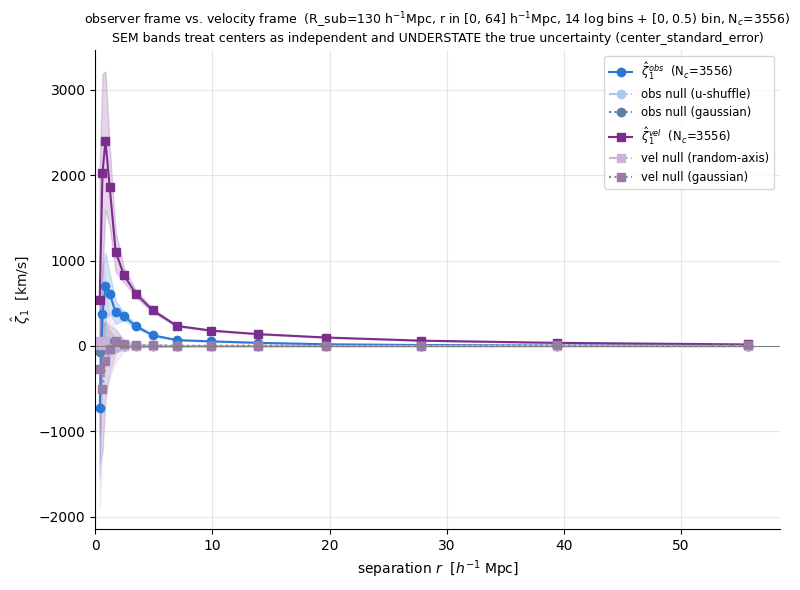

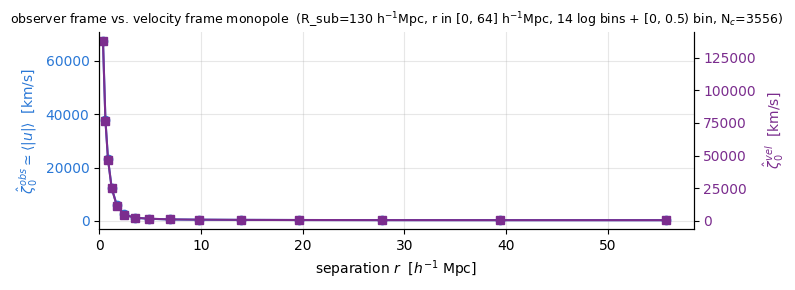

In [8]:
# The figures live in this notebook's own cell output -- no PNG is written
# anywhere. make_comparison_figure returns a DipoleFigures(dipole, monopole)
# -- two separate figures, never one merged image (CLAUDE.md hard rule 6);
# %matplotlib inline displays both.
figures = make_comparison_figure(cfg, results, comparison)

The cell below is the **binned companion** to the figure above: the same result, drawn flat across each shell's own edges rather than as a point joined by a line -- the lookup view of which shell a point belongs to and the value measured over it.

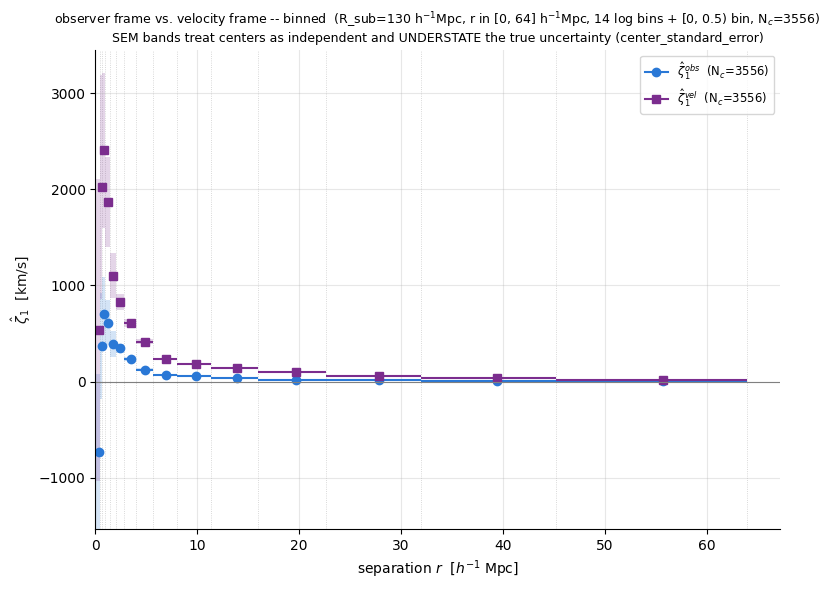

In [9]:
figures_binned = make_comparison_figure(cfg, results, comparison, binned=True)

## A.6 — Where the gap between the frames comes from

δ_α = arccos(v̂_α · ẑ_α^obs) is the angle between the two frames' axes for each centre. Because
*both* axes follow the motion, cos δ_α = |u_α| / |v_α| ≥ 0 and δ_α is capped at 90°: δ ≈ 0 is
the frame-agreement limit (a purely radial flow, in either direction), δ ≈ 90° is a purely
transverse flow, which the observer frame is blind to entirely.

**This is the diagnostic that most sharply separates a particle field from a halo field.** A
halo's velocity is a coherent bulk flow, so a halo sample sits well below the isotropic
reference. A *particle's* velocity is that bulk flow plus a virial component that has no
preferred orientation with respect to the line of sight — so the δ distribution here should
sit close to the isotropic P(δ) ∝ sin δ curve the bottom panel draws, with only a modest
low-δ excess from the coherent part. The median δ printed in §A.7 is the one-number version.

**Top panel** bins the per-centre dipole difference by δ_α: a few high-δ centres driving the
gap would mean bulk-flow contamination; a smooth spread means genuine projection geometry.

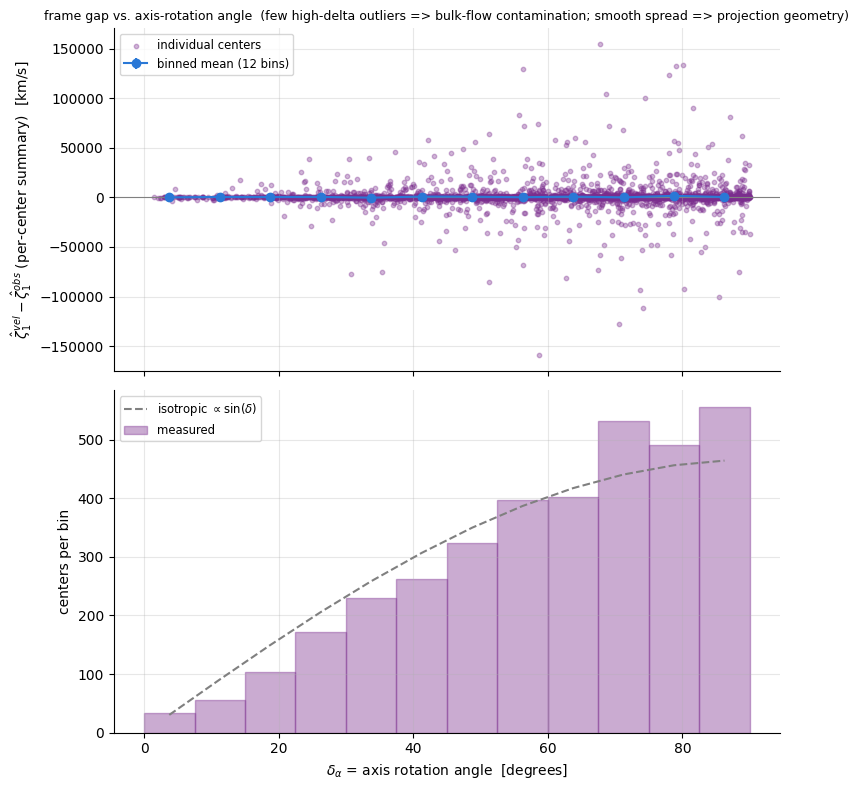

In [10]:
fig_angle = make_angle_diagnostic_figure(cfg, comparison)

## A.7 — Summary numbers

The shell-averaged amplitude of each frame, their ratio, and how far each null sits from zero
**in units of its own across-realization spread** — the right yardstick for a null, since that
spread is exactly how much the curve moves on a change of seed. O(1) means "indistinguishable
from zero", which is what all four should be.

The two mean speeds at the end are worth a second: for a velocity field that is isotropic with
respect to the line of sight, ⟨|u|⟩ / ⟨|v|⟩ = 1/2 exactly (the mean of |cos θ| over a sphere).
Reading close to 0.5 says the centre velocities are close to isotropic about the observer's
lines of sight, which is what a particle field dominated by virial motion should give; a value
meaningfully above 0.5 would mean residual coherent radial flow across the sample.

The resolved-shell mask is applied where it matters: shell-averaging over the four shells
inside `resolved_min_radius` (below the interparticle spacing) would let a resolution artifact
set the headline number.

In [11]:
delta_deg = np.degrees(comparison.per_center_delta)
resolved = comparison.shell_centers >= resolved_min_radius   # drop the shells inside the resolution floor

print(f"N_c = {centers.n_centers} centers, {resolved.sum()} resolved shells "
      f"({comparison.shell_centers[resolved][0]:.1f} - {comparison.shell_centers[-1]:.1f} h^-1 Mpc)")
print()
mean_obs = np.abs(comparison.obs.zeta_hat[resolved]).mean()
mean_vel = np.abs(comparison.vel.zeta_hat[resolved]).mean()
print(f"shell-averaged |zeta_hat|  obs : {mean_obs:8.2f} km/s")
print(f"shell-averaged |zeta_hat|  vel : {mean_vel:8.2f} km/s")
print(f"                     vel / obs : {mean_vel / mean_obs:8.2f}")
print()
print(f"null / own spread  obs (u-shuffle)   : {np.nanmean(np.abs(comparison.obs.zeta_hat_shuffle) / comparison.obs.null_spread_shuffle):8.2f}")
print(f"null / own spread  obs (gaussian)    : {np.nanmean(np.abs(comparison.obs.zeta_hat_gaussian) / comparison.obs.null_spread_gaussian):8.2f}")
print(f"null / own spread  vel (random-axis) : {np.nanmean(np.abs(comparison.vel.zeta_hat_shuffle) / comparison.vel.null_spread_shuffle):8.2f}")
print(f"null / own spread  vel (gaussian)    : {np.nanmean(np.abs(comparison.vel.zeta_hat_gaussian) / comparison.vel.null_spread_gaussian):8.2f}")
print("   (all four should be O(1) if the nulls are flat)")
print()
print("signal / null spread  obs :", np.round(comparison.obs.zeta_hat / comparison.obs.null_spread_shuffle, 1))
print("signal / null spread  vel :", np.round(comparison.vel.zeta_hat / comparison.vel.null_spread_shuffle, 1))
print()
# The monopole, with matter clustering divided out. Each monopole is (mean SPEED)
# x (occupancy ratio), and that ratio IS 1 + xi_mm(r) -- unbiased here, since the
# tracers ARE the matter. What is left after dividing it out is the genuine
# speed-density correlation, shared by both frames.
occupancy = obs_result.pair_count / (
    obs_result.n_centers * expected_shell_occupancy(n_bar, obs_result.shell_edges)
)
print("occupancy ratio 1+xi_mm(r) :", np.round(occupancy, 3),
      "  <- UNBIASED matter autocorrelation (b = 1)")
print()
obs_resid = comparison.obs.monopole_norm / occupancy
vel_resid = comparison.vel.monopole_norm / occupancy
print("monopole / (1+xi_mm)  obs :", np.round(obs_resid, 1))
print("                      vel :", np.round(vel_resid, 1))
print(f"   residual change over the resolved range   "
      f"obs: {100 * (obs_resid[-1] / obs_resid[resolved][0] - 1):+.1f}%   "
      f"vel: {100 * (vel_resid[-1] / vel_resid[resolved][0] - 1):+.1f}%")
print()
print(f"   <|u|> = {obs_result.per_center_speed.mean():.1f} km/s, "
      f"<|v|> = {vel_result.per_center_speed.mean():.1f} km/s, "
      f"ratio = {obs_result.per_center_speed.mean() / vel_result.per_center_speed.mean():.3f} "
      f"(isotropic expectation: 0.500)")
print()
print(f"delta_alpha : median {np.median(delta_deg):.1f} deg, "
      f"{(delta_deg < 30).sum()} centers below 30 deg, max {delta_deg.max():.1f} deg (ceiling 90)")
print("   (isotropic P(delta) ~ sin(delta) on [0, 90] has median 60.0 deg -- a particle")
print("    field should sit near it; a halo field would sit well below)")

N_c = 3556 centers, 11 resolved shells (1.7 - 54.6 h^-1 Mpc)

shell-averaged |zeta_hat|  obs :   118.01 km/s
shell-averaged |zeta_hat|  vel :   338.76 km/s
                     vel / obs :     2.87

null / own spread  obs (u-shuffle)   :     0.22
null / own spread  obs (gaussian)    :     0.29
null / own spread  vel (random-axis) :     0.09
null / own spread  vel (gaussian)    :     1.94
   (all four should be O(1) if the nulls are flat)

signal / null spread  obs : [-1.4  1.3  3.6  4.9  7.  14.7 23.3 18.8 20.8 16.5 21.8 16.4 15.7  9.7
 18. ]
signal / null spread  vel : [ 0.3  1.6  3.7  5.4  5.6 14.1 25.6 26.  32.2 32.3 34.8 44.9 37.5 36.5
 32. ]

occupancy ratio 1+xi_mm(r) : [163.956  85.155  50.536  27.07   12.943   5.981   3.423   2.438   1.813
   1.546   1.329   1.203   1.122   1.082   1.062]   <- UNBIASED matter autocorrelation (b = 1)

monopole / (1+xi_mm)  obs : [411.3 443.9 456.9 457.9 449.2 402.8 352.7 327.8 305.2 297.4 291.8 279.6
 269.7 266.3 263.9]
                      vel

# §B — Real space vs. redshift space

The notebook-07 comparison, on this box. The **same** observer-frame estimator is run twice on
a shared centre set: once on real box positions, once on redshift-space positions — every
particle displaced along its own line of sight by its own radial peculiar velocity
(`dvcorr.redshift_space.to_redshift_space`). The snapshot is at z = 0 exactly, so in comoving
box coordinates that displacement is **exact**, not an approximation, and `v_r / 100` is exact
for any cosmology because H₀ = 100 h km/s/Mpc *is* the definition of h⁻¹ Mpc.

The fact worth carrying into the plots: the displacement is purely radial, so it does not
rotate n̂ — and since u_α = v_α · n̂_V,α depends only on n̂ and v, **u_α is identical between the
two runs**. What changes is *shell composition only*: which tracers land in which radial bin
around a given centre. Never a centre's axis, never its weight.

### Why this box should show a much larger RSD effect than MDPL2 did

The rms radial displacement is σ(v_r) / 100 in h⁻¹ Mpc. On a **particle** field that is the
full one-dimensional velocity dispersion including virial motion — **3.6 h⁻¹ Mpc** for this
centre population, against a fraction of that for a halo catalog whose velocities are bulk
flows. So the fingers-of-God smearing reaches out to separations of order 3–15 h⁻¹ Mpc, which
is a large part of the range being measured. Expect the two curves to part company badly at small r
and converge only well beyond that scale. §B.6 puts a number on where.

## B.1 — The buffered load (run in §A.2)

Tracers displace too, so a plain `R_sub` carve leaves the redshift-space tracer field
incomplete at the boundary in *both* directions. The fix is to carve at `R_sub + v_margin`
first, where `v_margin` is derived from the plain carve's own |v_r|. The load itself already
ran in §A.2, because the shared centre set needs `v_margin`; this cell reads off what it
produced, and checks that its plain carve is §A's tracer field particle for particle.

**`v_margin_statistic = "percentile"`, not the default `"max"`.** This is the one place the
small box genuinely bites. The fastest particle in the carve moves at ~2900 km/s, so a
`"max"` margin is ~29 h⁻¹ Mpc — buffering to 159 h⁻¹ Mpc, past the 150 ceiling, and shrinking
the effective core radius to `130 − (64 + 29) = 37` (a ~2% candidate survival). At the 99.9th
percentile the margin is ~15 h⁻¹ Mpc, the buffer lands at ~145 inside the ceiling, and ~6% of
candidates survive.

What that costs is stated rather than hidden: the percentile margin is **not** a true bound on
the displacement, so 0.1% of tracers are still under-buffered and the boundary-flux gap
printed below comes out near 1.5% instead of "well under 1%". The pipeline compensates with a
sign-symmetric, position-independent **global |v_r| cut** on centres — legitimate where a cut
on the displaced position would not be — and prints how many that drops. `check_run_geometry`
re-runs on the buffered radius as soon as it exists, so a margin that would overflow the box
raises rather than silently wrapping.

In [12]:
print("v_margin_statistic :", rcfg.v_margin_statistic, "at percentile", rcfg.v_margin_percentile)
print()
print(f"v_margin        = {buffer.v_margin_kms:.1f} km/s = {buffer.v_margin_mpc:.2f} h^-1 Mpc")
print(f"buffered radius = {buffer.buffered_radius:.2f} h^-1 Mpc  (ceiling {box.max_analysis_radius:.0f})")
print(f"effective core  = {rcfg.sub_volume_radius - rcfg.shells.max_radius - buffer.v_margin_mpc:.1f} h^-1 Mpc"
      f" -> {100 * ((rcfg.sub_volume_radius - rcfg.shells.max_radius - buffer.v_margin_mpc) / rcfg.sub_volume_radius) ** 3:.1f}% of candidates")
print()
# The plain carve inside the buffered load is sec.A's tracer field, row for row.
print("buffer.pos_core is sec.A's carved.pos:", np.array_equal(buffer.pos_core, carved.pos))

v_margin_statistic : percentile at percentile 99.9

v_margin        = 1545.8 km/s = 15.46 h^-1 Mpc
buffered radius = 145.46 h^-1 Mpc  (ceiling 150)
effective core  = 50.5 h^-1 Mpc -> 5.9% of candidates

buffer.pos_core is sec.A's carved.pos: True


## B.2 — Build the tracer fields in both spaces

Displace the **full buffered** tracer field, then restrict back down to `R_sub` — restricting
first would throw away exactly the boundary tracers the buffer exists to keep. The flux check
printed below is this step's trust diagnostic; see B.1 for why it reads ~1.5% here rather than
under 1%, and why that is the percentile margin's known price rather than a misconfiguration.

In [13]:
tracers = build_tracer_spaces(rcfg, buffer, observer)

print()
print(f"real-inside-R_sub = {tracers.n_real_inside:,}, redshift-inside-R_sub = {tracers.n_redshift_inside:,}")

tracer flux check: real-inside-R_sub = 1954394, redshift-inside-R_sub = 1984355 (gap = 1.533%; expected well under 1% -- the buffer captures inflow and outflow both, so a much larger gap means the buffer is misconfigured, not that RSD moved a meaningfully large fraction of the tracer mass); 4 of 2680714 buffered tracers dropped by the through-observer flip guard before the R_sub restriction

real-inside-R_sub = 1,954,394, redshift-inside-R_sub = 1,984,355


## B.3 — The shared centre set (selected in §A.2)

Selected once, in §A.2, from candidates drawn out of the **plain**-radius carve — a candidate
centre must itself be a real member of the analysis sub-volume — and used by all four curves:
both §A frames and both §B spaces.

Three sequential cuts, all on **real** positions: the core cut at the *widened* margin
`r_max + v_margin`; the global |v_r| cut the percentile statistic requires; and the
through-observer flip guard. Selecting on a *displaced* position would be a real bias, not an
inelegance — it would systematically drop outward-movers near the far boundary while keeping
inward-movers, skewing ⟨u⟩ with position.

In [14]:
print(f"n_centers = {rs_centers.n_centers} (shared by both spaces, and by both sec.A frames)")
print(f"  dropped by the global |v_r| cut : {rs_centers.n_dropped_v_r_percentile}")
print(f"  dropped by the flip guard       : {rs_centers.n_dropped_flip}")
print()
print("sec.A's centre arrays are sec.B's real-space ones:",
      centers.s_centers is rs_centers.s_centers_real and centers.v_centers is rs_centers.v_centers)

n_centers = 3556 (shared by both spaces, and by both sec.A frames)
  dropped by the global |v_r| cut : 10
  dropped by the flip guard       : 0

sec.A's centre arrays are sec.B's real-space ones: True


## B.4 — Run both spaces, normalize, plot

`velocity_centered_shell_dipole` is called twice, completely unchanged, with the same
`v_centers`, `shell_edges`, `sub_volume_radius` and `observer`. Both are normalized with the
**same** n̄ — a per-run n̄ would fold the boundary-flux difference into the amplitude ratio,
which is the headline quantity here.

In [15]:
rs_results = run_both_spaces(rcfg, rs_centers, tracers, observer)
print()

rs_n_bar = snapshot_number_density(buffer.n_total, box)
rs_comparison = normalize_redshift_comparison(rcfg, rs_results, rs_n_bar)

print(f"n_bar = {rs_comparison.n_bar:.5f} particles / (h^-1 Mpc)^3")
print()
print("r_cen :", np.round(rs_comparison.shell_centers, 1))
print("real  :", np.round(rs_comparison.real.zeta_hat, 1))
print("rsd   :", np.round(rs_comparison.redshift.zeta_hat, 1))
print("ratio :", np.round(rs_comparison.redshift.zeta_hat / rs_comparison.real.zeta_hat, 2))


n_bar = 0.20713 particles / (h^-1 Mpc)^3

r_cen : [ 0.2  0.6  0.9  1.2  1.7  2.4  3.4  4.8  6.8  9.7 13.7 19.3 27.3 38.6
 54.6]
real  : [-730.2  369.6  704.3  611.8  393.7  346.9  231.   124.7   69.4   54.4
   37.2   20.1   11.3    4.3    5.1]
rsd   : [-156.8 -212.1 -233.5 -225.7 -198.1 -184.  -149.8 -100.6  -58.2  -23.9
   -5.5    1.8    1.     1.9    7.6]
ratio : [ 0.21 -0.57 -0.33 -0.37 -0.5  -0.53 -0.65 -0.81 -0.84 -0.44 -0.15  0.09
  0.09  0.44  1.49]


### Reading the figure

`make_redshift_comparison_figure` returns a `DipoleFigures(dipole, monopole)`
-- two separate figures (CLAUDE.md hard rule 6), not a merged two-panel image.

**Dipole figure:** ζ̂₁ in both spaces with their own SEM bands and their own two nulls (four distinct
random streams). **Monopole figure:** both monopoles on a *single* shared y-axis — unlike §A.5's twin
axes, these are the same kind of quantity, Σ|u_α| N_α,b, on the **same** u_α values, differing
only through shell occupancy. Any trend difference between the two monopole curves therefore
comes from occupancy alone.

**The redshift-space dipole goes negative at small separations.** That is not an orientation
bug and not a resolution artifact — it is fingers-of-God, and it is the main result of this
half. Around a moving centre, the virial velocities of nearby tracers scatter them along the
line of sight by ~3.6 h⁻¹ Mpc rms, which at small r overwhelms the real infall pattern and
inverts the near/far asymmetry the dipole measures. The monopole figure shows the same event
from the other side: the real-space one-halo pile in the inner bins is smeared *out* in
redshift space, so the redshift-space monopole is **lower** than the real-space one at small r
and higher at intermediate r.

The crossover is the number to take away, and §B.6 prints it: the two curves should agree
again once r is comfortably larger than the rms radial displacement, which is where the
Kaiser (linear, coherent) part of RSD is all that survives.

Both figures start at r = 0 (CLAUDE.md hard rule 10: each shell is one point at its
volume-weighted radius, the points are joined by a line, and the x-axis is pinned to begin at
the origin). That holds in **both** spaces for the same reason as in §A.5: a redshift-space
displacement is purely radial, so it cannot give a coincident pair a direction either. That is
what makes the negative inner branch a genuine *turn* back toward the origin rather than a
constant offset: the redshift-space curve's innermost point (−157 km/s) is already on its way
back from the −234 km/s trough at r ≈ 0.9. The binned companion after each figure draws the
same arrays flat across each shell's own edges, so any point can be matched to its shell.

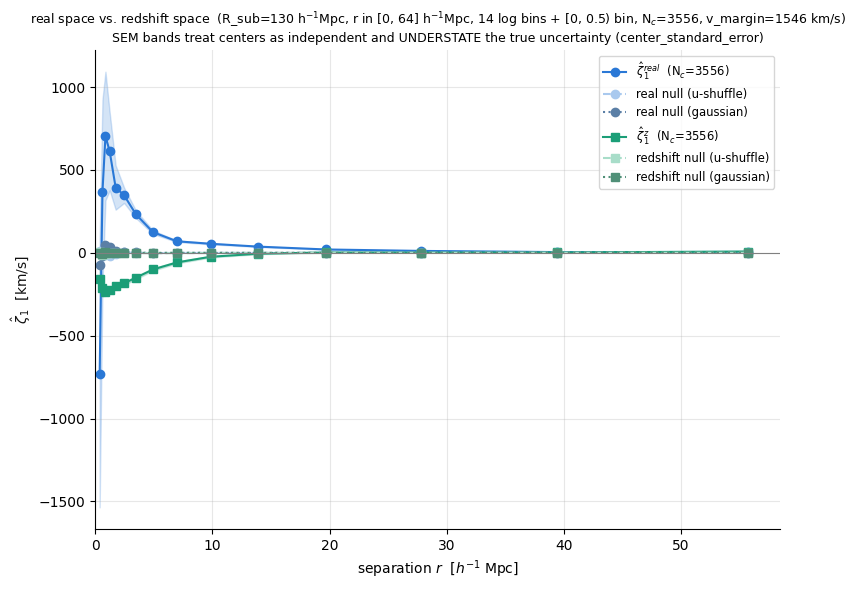

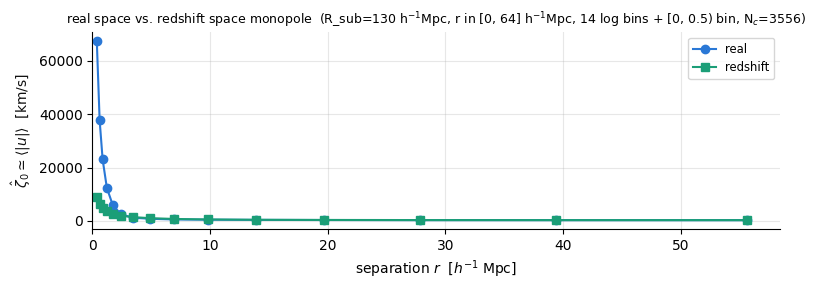

In [16]:
# DipoleFigures(dipole, monopole) -- two separate figures (hard rule 6).
figures_rs = make_redshift_comparison_figure(rcfg, rs_results, rs_comparison)

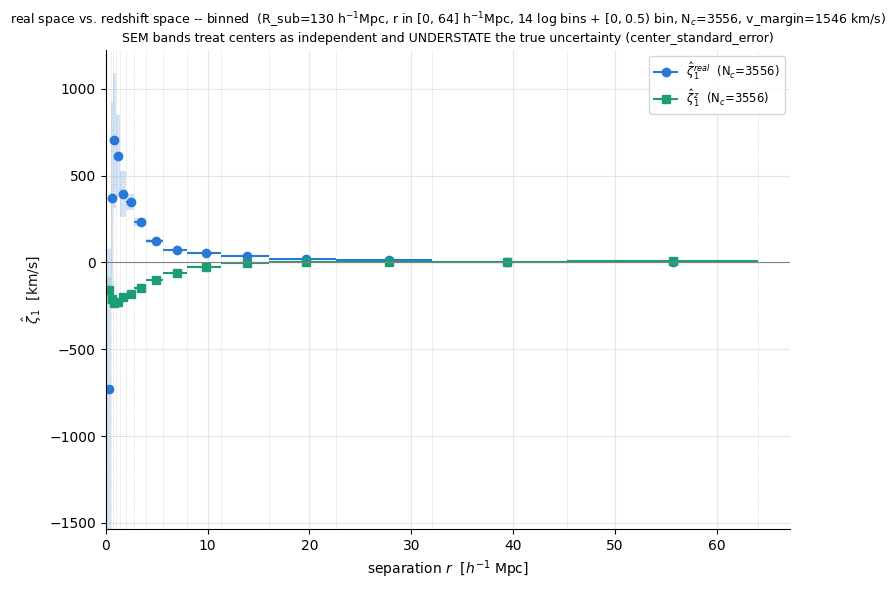

In [17]:
figures_rs_binned = make_redshift_comparison_figure(
    rcfg, rs_results, rs_comparison, binned=True
)

## B.5 — One centre, and membership churn

The same dipole-figure-plus-monopole-companion split (`DipoleFigures`, CLAUDE.md hard
rule 6) for a **single** centre (`cfg.example_center_index`), both spaces
overlaid on each figure, with no error band — one centre has no across-centre population to form one from.

Then the membership diagnostic: a standalone routine (deliberately *not* part of the
estimator) that re-queries both tracer fields around the shared centres' real positions and
compares shell membership by **stable buffer-row id**, never by array index —
`s_tracers_real` and `s_tracers_redshift` are different subsets of the same buffer, so row *i*
of one and row *i* of the other are, in general, different particles.

`net_change` alone can be near zero while membership churns completely underneath, which is
why the churn columns are reported beside it. On this box the churn is large wherever the
3.6 h⁻¹ Mpc rms displacement is comparable to or larger than the shell width: above 0.9 out to
r ≈ 2 and still ~0.6 at r ≈ 10. It falls to ~0.2 only in the outermost, 19 h⁻¹ Mpc wide, shell.

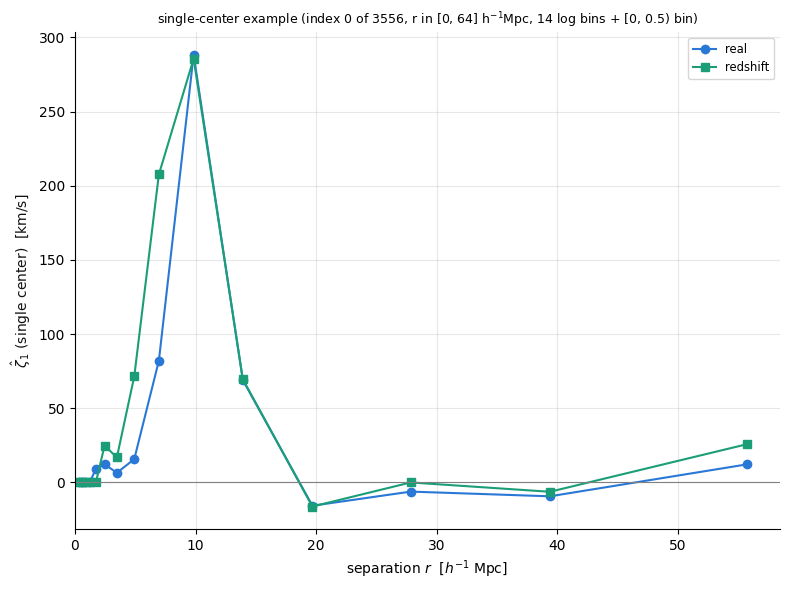

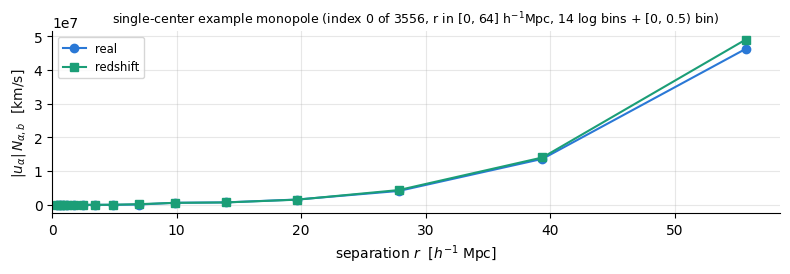

In [18]:
# DipoleFigures(dipole, monopole) -- two separate figures (hard rule 6).
figures_single = make_single_center_figure(rcfg, rs_results, rs_comparison.n_bar)

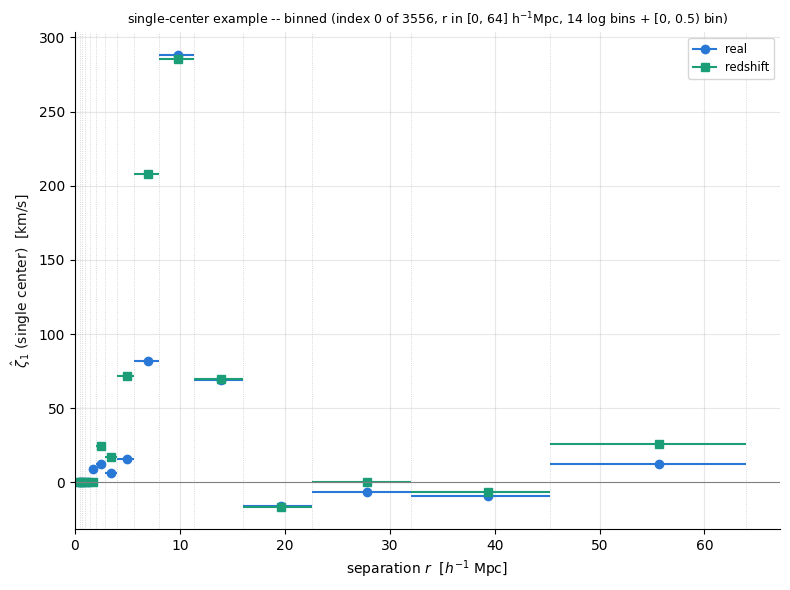

In [19]:
figures_single_binned = make_single_center_figure(
    rcfg, rs_results, rs_comparison.n_bar, binned=True
)

In [20]:
diagnostics = membership_diagnostics(
    rs_centers.s_centers_real,
    tracers.s_tracers_real, tracers.real_ids,
    tracers.s_tracers_redshift, tracers.redshift_ids,
    rcfg.shells.shell_edges,
)

print(f"{'r':>6}  {'net_change':>12}  {'only_real':>12}  {'only_rsd':>12}  {'both':>12}  {'churn frac':>10}")
for b, r in enumerate(diagnostics.shell_centers):
    only_r = diagnostics.churn_only_real[b]
    only_s = diagnostics.churn_only_redshift[b]
    both = diagnostics.churn_intersection[b]
    frac = (only_r + only_s) / (only_r + only_s + both) if (only_r + only_s + both) else np.nan
    print(f"{r:6.1f}  {diagnostics.net_change[b]:+12.0f}  {only_r:12.0f}  {only_s:12.0f}  {both:12.0f}  {frac:10.3f}")

     r    net_change     only_real      only_rsd          both  churn frac
   0.2        -53091         59144          6053          4086       0.941
   0.6        -46187         56966         10779          3080       0.957
   0.9        -69565         93566         24001          7224       0.942
   1.2        -86283        137550         51267         15156       0.926
   1.7        -70268        176791        106523         29712       0.905
   2.4          -480        207650        207170         62263       0.869
   3.4        +99206        290256        389462        146607       0.823
   4.8       +206244        498171        704415        382126       0.759
   6.8       +399524        873957       1273481        977446       0.687
   9.7       +460818       1722997       2183815       2741737       0.588
  13.7       +906817       3131485       4038302       7726053       0.481
  19.3      +1905183       5824765       7729948      21963680       0.382
  27.3      +4003526     

## B.6 — Summary numbers

The shell-averaged amplitude in each space, the ratio, and the scale the whole §B story turns
on: the rms radial displacement σ(v_r)/100, in the same h⁻¹ Mpc the shells are binned in. The
crossover radius — where the redshift-space dipole recovers the sign of the real-space one —
is reported against it.

In [21]:
rs_resolved = rs_comparison.shell_centers >= resolved_min_radius
r_cen = rs_comparison.shell_centers
ratio = rs_comparison.redshift.zeta_hat / rs_comparison.real.zeta_hat

mean_real = np.nanmean(rs_comparison.real.zeta_hat[rs_resolved])
mean_rsd = np.nanmean(rs_comparison.redshift.zeta_hat[rs_resolved])

print(f"N_c = {rs_centers.n_centers} centers (shared), {rs_resolved.sum()} resolved shells")
print(f"v_margin = {rs_centers.v_margin_kms:.1f} km/s = {rs_centers.v_margin_mpc:.2f} h^-1 Mpc")
print()
print(f"shell-averaged zeta_hat_1 : real = {mean_real:.2f} km/s, redshift = {mean_rsd:.2f} km/s, "
      f"ratio = {mean_rsd / mean_real:.3f}")
print()
# The scale the whole section turns on: how far RSD moves a tracer along the line
# of sight. 100 = H0 in km/s per h^-1 Mpc at z = 0 -- definitional, not tunable.
v_r_centers = np.einsum(
    "ij,ij->i",
    rs_centers.v_centers,
    (rs_centers.s_centers_real - observer)
    / np.linalg.norm(rs_centers.s_centers_real - observer, axis=1)[:, None],
)
sigma_v_r = float(np.std(v_r_centers))
print(f"sigma(v_r) over centers      = {sigma_v_r:.1f} km/s")
print(f"  -> rms radial displacement = {sigma_v_r / 100.0:.2f} h^-1 Mpc   <- the fingers-of-God scale")
print()
sign_flip = ratio < 0
if sign_flip[rs_resolved].any():
    last_negative = r_cen[rs_resolved][sign_flip[rs_resolved]].max()
    first_positive = r_cen[rs_resolved][~sign_flip[rs_resolved]].min()
    print(f"redshift-space dipole is NEGATIVE out to r = {last_negative:.1f} h^-1 Mpc, "
          f"positive from r = {first_positive:.1f}")
    print(f"  crossover / rms displacement = {first_positive / (sigma_v_r / 100.0):.1f}")
else:
    print("redshift-space dipole keeps the real-space sign on every resolved shell")
print()
print("ratio by shell :", np.round(ratio, 2))
print(f"tracer flux    : real-inside-R_sub = {tracers.n_real_inside:,}, "
      f"redshift-inside-R_sub = {tracers.n_redshift_inside:,}")

N_c = 3556 centers (shared), 11 resolved shells
v_margin = 1545.8 km/s = 15.46 h^-1 Mpc

shell-averaged zeta_hat_1 : real = 118.01 km/s, redshift = -64.35 km/s, ratio = -0.545

sigma(v_r) over centers      = 357.1 km/s
  -> rms radial displacement = 3.57 h^-1 Mpc   <- the fingers-of-God scale

redshift-space dipole is NEGATIVE out to r = 13.7 h^-1 Mpc, positive from r = 19.3
  crossover / rms displacement = 5.4

ratio by shell : [ 0.21 -0.57 -0.33 -0.37 -0.5  -0.53 -0.65 -0.81 -0.84 -0.44 -0.15  0.09
  0.09  0.44  1.49]
tracer flux    : real-inside-R_sub = 1,954,394, redshift-inside-R_sub = 1,984,355


# What this box is for

Three things this run gives that the MDPL2 arm cannot, and one caveat that limits all of them.

**1 — an unbiased calibration point.** The `1 + ξ_mm(r)` occupancy ratio printed in §A.7 is
the *matter* autocorrelation, measured on the same shells and with the same code path as the
halo-biased version notebook 09 works with. That makes it a direct calibration target for
`dvcorr.pipeline.galaxy_bias`: b(r) is the ratio of the two, measured rather than modelled.

**2 — the RSD effect at full strength.** §B's sign flip is the same physics MDPL2 shows
weakly, on a field where the velocity dispersion entering it is the true matter dispersion
rather than a halo catalog's. It is the cleanest available check that the redshift-space
machinery does what it claims.

**3 — a constrained volume.** If the 2MRS provenance is confirmed, this is a mock of the
actual local volume rather than a statistically equivalent one, and its 150 h⁻¹ Mpc reach
brackets CF4's useful depth. That makes it a candidate for a *direct* comparison against the
real measurement later, not only a statistical one. Ask about the rest of the chain: if
`ichain0` is one of several samples, the others are a covariance ensemble — which is exactly
what the empty `mocks/` arm is waiting for.

**The caveat: resolution.** At 1.37e11 h⁻¹ M☉ per particle this box cannot host a halo
catalog comparable to MDPL2's — a 10¹³ h⁻¹ M☉ group is 73 particles, and
`conventions.CONVERGED_PARTICLE_COUNT` = 100 puts the velocity-converged floor at
1.4e13. So this box answers questions about the *matter* field, and MDPL2 answers questions
about *tracers*. Neither substitutes for the other.

# §C — What happens near zero? The five tests

§A and §B share a centre set (A.2) and, on the default ladder, read **−730.2 km/s** in the
innermost `[0, 0.5)` h⁻¹ Mpc bin: a *negative* value, against +369.6 and +704.3 in the next two
shells. Read as a curve, that looks like the correlation collapsing and reversing inside the
virial radius. Read as a statistic, it might be one draw of a very noisy number: it sits 1.4 of
its own null spreads from zero. (On the earlier r_max = 40 ladder the same question was raised
by a lumped `[0, 2)` bin, which read 80.4 km/s on this kind of centre set and 301.9 on a larger
one.)

**This section decides which, and it is not about that bin.** The five tests below are the
general recipe for "is this shell a measurement?", and `dvcorr.pipeline.robustness` is where
they live — this notebook only wires them together, as everywhere else here.

| # | test | what it asks | function |
|---|---|---|---|
| 1 | **precision ladder** | does the scatter fall as 1/√N_c, and does the quoted SEM match it? | `precision_ladder` |
| 2 | **bootstrap interval** | what does a *distribution-free* interval say, given the terms are not Gaussian? | `bootstrap_confidence` |
| 3 | **trim ladder** | how much of the answer rides on its largest few contributors? | `trim_ladder` |
| 4 | **seed repeats** | does a freshly drawn centre set reproduce it? | `seed_repeats` |
| 5 | **mechanism split** | does the variable the *explanation* names actually order the result? | `crowding_split`, `speed_split` |

Tests 1, 2, 3 and 5 cost **no estimator pass at all**: they are re-sums of `per_center_dipole`,
`per_center_count` and `per_center_speed`, arrays the estimator already returned — the same
recombination discipline every null in this package follows. `restack(stack)` over all centres
reproduces `normalize_stacked_dipole` exactly (pinned in `tests/test_robustness.py`), which is
what licenses plotting a subset curve on the same axes as the published one. Only test 4 runs
the estimator, once per seed.

### Three deliberate choices

**This ladder is a confirmed departure from rule 10.** CLAUDE.md hard rule 10 makes `[0, 0.5)`
plus 14 log shells to 64 the default, and §A, §B and §D use it. §C deliberately does not: it is
a zoom on the regime near zero, and its edges, `[0, 0.2, 0.277, …, 7.22, 10]`, were confirmed
by the user on 2026-10-05, as the rule requires.

**The inner region is resolved further.** §A and §B bin `[0, 0.5)` as a single shell, plotted
at its volume-weighted radius r = 0.375, and have five shells below 2 h⁻¹ Mpc on ~3500
centres. Here the ladder runs from the **force softening** in 12 log bins: **three shells
inside 0.5 h⁻¹ Mpc** where there was one, eight below 2 h⁻¹ Mpc, on 27× as many centres.

Why the softening and not §A's floor: §A treats every shell inside 1.41 h⁻¹ Mpc as unresolved
because `box.mean_interparticle_spacing` is 1.17 h⁻¹ Mpc, below which a *single centre's* shell holds
O(0) particles. That is the right floor for one centre and the wrong one for a stack. ζ̂₁ is a
sum over ~10⁵ centres, so a shell that is empty around any given centre is still populated by
tens of thousands of pairs in aggregate — the [0, 0.2) bin carries hundreds of expected pairs
per 10⁵ centres before clustering, and clustering multiplies that heavily. What genuinely
breaks below **0.20 h⁻¹ Mpc** is not the statistics but the *simulation*: that is Gadget's
force softening, inside which the gravity that produced these velocities was smoothed. So it is
the floor, and it is read from the file rather than typed in.

**Shells stop at r = 10, not 64.** The question is about small r, and the outer shells cost the
overwhelming majority of the runtime: a query ball scales as r³, so `r_max = 10` is ~260×
cheaper per centre than §A's 64. That is the whole trick that makes this section affordable:
it buys ~27× more centres than §A's set, and more centres is precisely what the question
needs. The figure then zooms to r ≤ 3 (`figure_max_radius`) so the resolved bins are legible;
every table still spans all twelve.

**Observer frame, real space only.** Neither frame's innermost bin clears its null in §A.7
(observer −1.4 null spreads, velocity 0.3), but only the observer frame's carries the anomalous
sign; and §B's redshift-space curve has its own well-understood sign flip. The bin under
suspicion is the observer frame's, in real space, so that is the only one measured here.


In [22]:
# sec.A's import cell brings in the draw and the shared-center cut, but not the
# estimator runner -- sec.A reaches the estimator through run_both_frames.
from dvcorr.pipeline.velocity_centered import run_estimator
from dvcorr.pipeline.robustness import (
    RobustnessRunConfig,
    per_center_stack,
    restack,
    precision_ladder,
    bootstrap_confidence,
    trim_ladder,
    seed_repeats,
    crowding_shell_index,
    merge_shells,
    crowding_split,
    speed_split,
    make_robustness_figure,
)

# A DELIBERATE DEPARTURE from CLAUDE.md hard rule 10's default ladder, confirmed
# by the user (2026-10-05): this section is a zoom on the regime near zero, so it
# runs from the force softening to 10 h^-1 Mpc instead of 0.5 to 64. See the
# markdown above for why the softening, not the interparticle spacing, is the
# floor for a stacked statistic. Both are read from the file, never typed in.
robust_shells = ShellConfig(
    min_radius=box.softening,
    max_radius=10.0,
    spacing=SPACING_LOG,
    n_bins=12,
    include_zero_bin=True,
)

# Environment is measured at the mean interparticle spacing -- the smallest
# scale at which a tracer count is a density rather than a coincidence -- and
# NOT in the shell under test, which would be circular (C.6).
crowding_shell = int(np.searchsorted(
    robust_shells.shell_edges, box.mean_interparticle_spacing, side="right"
) - 1)

rbcfg = RobustnessRunConfig(
    sub_volume_radius=SUB_VOLUME_RADIUS,
    shells=robust_shells,
    n_candidate_centers=120_000,   # ~20x sec.A, bought back by the shorter r range
    trim_rank_shell=0,             # the bin nearest zero -- what tests 3 and 5 report on
    crowding_shell=crowding_shell,
    figure_max_radius=3.0,         # plot-only zoom; every table still spans all shells
)

edges = rbcfg.shells.shell_edges
core_radius = rbcfg.sub_volume_radius - rbcfg.shells.max_radius
print("softening          :", box.softening, "h^-1 Mpc   <- the innermost LOG edge")
print("interparticle sp.  :", round(box.mean_interparticle_spacing, 3), "h^-1 Mpc")
print()
print("shell_edges        :", np.round(edges, 3))
print(f"shells inside {cfg.shells.min_radius:g}  :", int((edges[1:] <= cfg.shells.min_radius).sum()),
      f"  (sec.A and sec.B have 1: the single [0, {cfg.shells.min_radius:g}) bin)")
print()
print("trim_rank_shell    :", rbcfg.trim_rank_shell,
      f"-> [{edges[0]:g}, {edges[1]:g}) h^-1 Mpc")
print("crowding_shell     :", crowding_shell,
      f"-> [{edges[crowding_shell]:.3f}, {edges[crowding_shell + 1]:.3f}) h^-1 Mpc"
      f"   (brackets {box.mean_interparticle_spacing:.3f})")
print("figure_max_radius  :", rbcfg.figure_max_radius, "h^-1 Mpc (view only)")
print()
print("core radius        :", core_radius, "h^-1 Mpc"
      f" -> {100 * (core_radius / rbcfg.sub_volume_radius) ** 3:.1f}% of candidates survive"
      f"  (sec.A, at r_max = {cfg.shells.max_radius:.0f}:"
      f" {100 * ((cfg.sub_volume_radius - cfg.shells.max_radius) / cfg.sub_volume_radius) ** 3:.1f}%)")
print("n_candidate_centers:", f"{rbcfg.n_candidate_centers:,}")
print()
print("bootstrap resamples:", rbcfg.n_bootstrap, " confidence:", rbcfg.confidence)
print("subset fractions   :", rbcfg.subset_fractions, f"x {rbcfg.n_subset_draws} draws each")
print("trim counts        :", rbcfg.trim_counts)
print("seed repeats       :", rbcfg.n_seed_repeats)

softening          : 0.2 h^-1 Mpc   <- the innermost LOG edge
interparticle sp.  : 1.172 h^-1 Mpc

shell_edges        : [ 0.     0.2    0.277  0.384  0.532  0.737  1.021  1.414  1.959  2.714
  3.761  5.21   7.218 10.   ]
shells inside 0.5  : 3   (sec.A and sec.B have 1: the single [0, 0.5) bin)

trim_rank_shell    : 0 -> [0, 0.2) h^-1 Mpc
crowding_shell     : 6 -> [1.021, 1.414) h^-1 Mpc   (brackets 1.172)
figure_max_radius  : 3.0 h^-1 Mpc (view only)

core radius        : 120.0 h^-1 Mpc -> 78.7% of candidates survive  (sec.A, at r_max = 64: 13.1%)
n_candidate_centers: 120,000

bootstrap resamples: 2000  confidence: 0.95
subset fractions   : (0.02, 0.05, 0.1, 0.25, 0.5, 1.0) x 64 draws each
trim counts        : (0, 1, 10, 100, 1000)
seed repeats       : 4


## C.1 — One estimator pass

The tracer field is **§A's**, unchanged: `carved` was carved at the same `SUB_VOLUME_RADIUS`
with the same 1-in-3 thinning, and nothing about it depends on `max_radius`. Reusing it rather
than reloading is not just a time saving — it is what makes §C's numbers comparable to §A's
rather than merely similar to them. `uniform_mass` and `all_distinct` are §A.2's synthetic
signature-fillers, likewise reused and likewise read by nothing.

Only the centre draw is new, and it is much larger. The core cut is far kinder here
(`core_margin = r_max = 10` against §A and §B's `64 + 15.5`), so nearly four in five
candidates survive, against one in fifteen there.

Everything downstream then hangs off **one** `PerCenterStack`: the estimator's per-centre
arrays plus the cached normalization, bundled so that every test below re-sums the same
numbers rather than re-deriving them.

*Runtime: the estimator pass is ~1 minute; the whole section is ~6, dominated by test 4's four
extra passes.*

In [23]:
rb_candidates = draw_candidates_from_arrays(
    rbcfg, carved.pos, carved.vel, uniform_mass, all_distinct
)
print("candidate centers:", rb_candidates.s.shape[0])
print()

rb_centers = select_shared_centers(rbcfg, rb_candidates.s, rb_candidates.v, observer)
print()

rb_result = run_estimator(
    rbcfg, rb_centers.s_centers, rb_centers.v_centers, carved.pos, observer
)

# n_bar is sec.A's -- same field, same thinning, same box (see the markdown).
stack = per_center_stack(rb_result, n_bar)
full = restack(stack)

print()
print(f"N_c      : {stack.n_centers:,}   (sec.A and sec.B, shared: {centers.n_centers:,})")
print("r_cen    :", np.round(stack.shell_centers, 2))
print("zeta_hat :", np.round(full.zeta_hat, 1))
print("sem      :", np.round(full.sem, 1))
print("sem/|z|  :", np.round(full.sem / np.abs(full.zeta_hat), 3))
print("monopole :", np.round(full.monopole_norm, 1))   # hard rule 6

candidate centers: 120000

n_candidates = 120000 -> core cut (core_margin = 10.0) -> n_core = 96320 (80.3% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 96320 (0 dropped as too slow)



n_candidates = 96320, n_centers = 96320 (100.0% survive the core cut)

N_c      : 96,320   (sec.A and sec.B, shared: 3,556)
r_cen    : [0.1  0.24 0.33 0.46 0.63 0.88 1.22 1.69 2.34 3.24 4.49 6.21 8.61]
zeta_hat : [376.8 542.3 558.2 843.3 761.  657.1 512.9 381.3 259.  167.1 112.3  70.7
  49.4]
sem      : [274.4 250.5 200.8 151.6  99.3  59.5  33.   15.9   6.9   3.3   2.    1.
   0.6]
sem/|z|  : [0.728 0.462 0.36  0.18  0.13  0.091 0.064 0.042 0.027 0.02  0.018 0.014
 0.012]
monopole : [94477.1 72584.5 55044.8 38058.7 24008.  13745.1  7065.   3347.   1654.
   966.1   679.4   500.2   395.7]


## C.2 — Test 1: the precision ladder

Draw random centre subsets of increasing size, `n_subset_draws` of each, and watch two numbers
per rung: the **across-draw spread** (how much a stack that size actually moves) and the mean
**internal SEM** (how much it *says* it moves). Subsets are drawn without replacement, because
they stand in for smaller runs and a smaller run would not measure the same centre twice.

Three things to read off it:

- **`zeta_hat_mean` should be flat in N_c.** A subset mean is a mean, so it is unbiased at
  every rung by construction. A *trend* here would not be noise — it would mean the subsets
  are not exchangeable with the parent, i.e. a selection leaked into the draw.
- **spread ≈ SEM says the quoted error bar is honest** — but read that comparison at the
  *small* rungs. Sampling without replacement carries the finite-population correction
  `√((N_full − N)/(N_full − 1))`, so the spread necessarily sits ~√(1 − N/N_full) below the
  reference at large fractions: a subset that is half the parent shares half its centres with
  it and cannot scatter freely. That deficit is arithmetic, not good news. Test 4 is the
  version with no such correction.
- **The 1/√N_c reference line** turns "is the drop real?" into "how many centres would settle
  it?", which is a question with an answer you can act on. The last line prices §A's and §B's
  shared centre count on it.

The full rung's across-draw spread is exactly zero, on purpose: without replacement there is
only one way to draw the whole set. It stays in the table and is left off the log-scale panel,
where a zero has no place.

In [24]:
ladder = precision_ladder(rbcfg, stack)
b = rbcfg.trim_rank_shell

print(f"Innermost shell [{stack.shell_edges[0]:g}, {stack.shell_edges[1]:g}) h^-1 Mpc\n")
print(f"{'N_c':>8}  {'<zeta_hat>':>12}  {'across-draw':>12}  {'internal SEM':>13}  {'1/sqrt(N) ref':>14}")
for i, n in enumerate(ladder.n_centers):
    print(f"{n:8d}  {ladder.zeta_hat_mean[i, b]:12.1f}  {ladder.zeta_hat_spread[i, b]:12.1f}"
          f"  {ladder.sem_mean[i, b]:13.1f}  {ladder.reference_spread[i, b]:14.1f}")

# The centre count sec.A and sec.B share, priced on this ladder: how far a
# stack that size is expected to wander in this bin.
expected = full.sem[b] * np.sqrt(stack.n_centers / centers.n_centers)
print(f"\nsec.A / sec.B: N_c = {centers.n_centers:,} -> expected 1-sigma wander of ~{expected:.0f} km/s in this bin")

Innermost shell [0, 0.2) h^-1 Mpc

     N_c    <zeta_hat>   across-draw   internal SEM   1/sqrt(N) ref
    1926         288.4        2460.0         1942.1          1940.7
    4816         560.0        1212.6         1206.8          1227.3
    9632         474.8         850.5          864.3           867.8
   24080         330.1         517.2          548.0           548.8
   48160         379.8         270.8          388.3           388.1
   96320         376.8           0.0          274.4           274.4

sec.A / sec.B: N_c = 3,556 -> expected 1-sigma wander of ~1428 km/s in this bin


## C.3 — Test 2: the bootstrap interval

The SEM is a Gaussian statement about a sum whose terms are emphatically not Gaussian. The
bootstrap makes no such assumption: resample the **centres** with replacement and read a
percentile interval straight off the resampled stacks.

Centres are the right resampling unit. A centre is what the stack averages over, and its whole
shell — every tracer in it — travels with it, so the resample preserves exactly the
within-shell correlation that makes the per-centre contributions heavy-tailed in the first
place. Resampling tracers instead would break that and quietly report a much smaller interval.

The interval is reported as explicit low/high edges, never as a symmetric ±, because on the
inner shells it is not symmetric. `bootstrap_std` beside `sem` is the compact version of the
same comparison: a large gap between them *is* the non-Gaussianity, which test 3 then measures
directly.

**Comparing back to §A and §B needs `merge_shells`.** Their `[0, 0.5)` number is one bin; §C
covers about the same range with four narrow ones (merged to `[0, 0.532)`, the §C edge
nearest 0.5), and they cannot be compared by averaging — each shell's
normalization divides by its *own* n̄V_b, so a plain mean of the fine bins equals nothing in
particular. `merge_shells` does it correctly, summing the raw per-centre numerators and
normalizing once against the merged shell's own volume. That is exactly the number the coarse
run would have produced from these centres, and `tests/test_robustness.py` checks it against a
real coarse-binned estimator pass rather than against a re-derivation.

In [25]:
interval = bootstrap_confidence(rbcfg, stack)

print(f"{interval.confidence:.0%} percentile interval from {interval.n_resamples} resamples\n")
print(f"{'r_lo':>6} {'r_hi':>6}  {'zeta_hat':>10}  {'low':>10}  {'high':>10}  {'boot std':>9}  {'SEM':>9}  {'ratio':>6}")
for i in range(stack.shell_centers.size):
    print(f"{stack.shell_edges[i]:6.3f} {stack.shell_edges[i + 1]:6.3f}"
          f"  {interval.zeta_hat[i]:10.1f}  {interval.low[i]:10.1f}  {interval.high[i]:10.1f}"
          f"  {interval.bootstrap_std[i]:9.1f}  {interval.sem[i]:9.1f}"
          f"  {interval.bootstrap_std[i] / interval.sem[i]:6.2f}")

# --- the like-for-like comparison against sec.A / sec.B ----------------------
# Merge sec.C's inner shells into ONE bin, the counterpart of sec.A and sec.B's
# [0, min_radius). The merged edge is the sec.C ladder edge NEAREST min_radius,
# so it lands near it rather than exactly on it -- printed, not assumed.
n_inner = int(np.argmin(np.abs(stack.shell_edges - cfg.shells.min_radius)))
coarse = merge_shells(stack, [0, n_inner, stack.shell_centers.size])
coarse_curve = restack(coarse)
print(f"\nmerging sec.C's inner {n_inner} shells into one "
      f"[{coarse.shell_edges[0]:g}, {coarse.shell_edges[1]:.3f}) bin"
      f"   (sec.A / sec.B measured [0, {cfg.shells.min_radius:g}))")
print(f"  sec.C, merged : {coarse_curve.zeta_hat[0]:8.1f} +/- {coarse_curve.sem[0]:.1f} km/s"
      f"   (N_c = {coarse.n_centers:,})")
print(f"  sec.A / sec.B : {comparison.obs.zeta_hat[0]:8.1f} km/s   (N_c = {centers.n_centers:,};"
      " sec.A obs and sec.B real are one curve)")

# Does the bin nearest zero sit on the inward continuation of the ones outside
# it? The outer bins rise inward by a near-constant factor, so extrapolating
# one bin further is a fair expectation to test the measurement against.
step = interval.zeta_hat[1] / interval.zeta_hat[2]
print(f"\nbin-to-bin rise just outside the innermost: {step:.2f}x")
print(f"  extrapolated expectation for [{stack.shell_edges[0]:g}, {stack.shell_edges[1]:g}): "
      f"{interval.zeta_hat[1] * step:.1f} km/s")
print(f"  measured                                 : {interval.zeta_hat[b]:.1f} km/s"
      f"  [{interval.low[b]:.1f}, {interval.high[b]:.1f}]")

95% percentile interval from 2000 resamples

  r_lo   r_hi    zeta_hat         low        high   boot std        SEM   ratio
 0.000  0.200       376.8      -144.9       911.3      273.2      274.4    1.00
 0.200  0.277       542.3        31.9      1048.6      257.4      250.5    1.03
 0.277  0.384       558.2       166.5       971.1      205.1      200.8    1.02
 0.384  0.532       843.3       544.7      1139.0      155.5      151.6    1.03
 0.532  0.737       761.0       555.5       969.5      103.4       99.3    1.04
 0.737  1.021       657.1       536.5       776.3       61.4       59.5    1.03
 1.021  1.414       512.9       446.6       571.7       32.4       33.0    0.98
 1.414  1.959       381.3       351.5       412.6       15.7       15.9    0.99
 1.959  2.714       259.0       245.7       271.9        6.8        6.9    0.99
 2.714  3.761       167.1       160.8       173.6        3.2        3.3    0.97
 3.761  5.210       112.3       108.4       116.2        2.0        2.0    

## C.4 — Test 3: the trim ladder

Drop the k largest-|contribution| centres and restack. Ranking is on the **absolute** value,
both signs: trimming only the positive tail would be a biased estimator wearing a robustness
check's clothes — it would drag every stack downward by construction and make any feature look
fragile.

The ranking comes from **one** shell (`trim_rank_shell`, here the one nearest zero). It has to:
the centre that dominates the inner bin is not the one that dominates the outer bins, and
re-ranking per shell would trim a different sample in every column — which is not a subset of
anything and has no interpretation.

What to expect, and what would be damning:

- The value **will** move. The distribution is heavy-tailed; `mean / median` says how badly —
  except on a shell narrow enough that most centres hold no tracer at all, where the median is
  exactly 0 and `n_contributing` is the number that means something. Resolving down to the
  softening puts the innermost bin firmly in that regime, so the ladder reports the fraction of
  centres that contribute at all.
- What must survive is the **sign and the order of magnitude**. A stack that halves when you
  drop 0.1% of its centres is still telling you something; a stack that crosses zero is not.
- The **monopole** is printed beside it (hard rule 6) and does double duty here: a trim that
  also moves the monopole has changed which *shells* are represented, not just which
  velocities, and its dipole is then not comparable to the untrimmed one.

In [26]:
trim = trim_ladder(rbcfg, stack)

contributing = trim.n_contributing / trim.n_centers[0]
print(f"ranked on shell [{stack.shell_edges[b]:g}, {stack.shell_edges[b + 1]:g}) h^-1 Mpc")
print(f"centers contributing at all: {trim.n_contributing:,} of {trim.n_centers[0]:,}"
      f"  ({contributing:.1%})")
print(f"per-center contribution there: mean = {trim.mean_contribution:.2f} km/s, "
      f"median = {trim.median_contribution:.2f} km/s")
if trim.median_contribution != 0.0:
    print(f"  -> mean/median = {trim.mean_contribution / trim.median_contribution:.0f}x")
else:
    # Not a degenerate case to guard around -- see C.4. Over half the centers
    # are empty in this shell, so the median IS zero and the informative
    # comparison is against the contributing centers only.
    among = np.median(
        np.abs(stack.per_center_dipole[:, b] * stack.norm_scale[b])[
            stack.per_center_dipole[:, b] != 0.0
        ]
    )
    print(f"  -> median is 0 because {1 - contributing:.1%} of centers are EMPTY here;"
          f" median |contribution| among contributors = {among:.1f} km/s")
print()

print(f"{'dropped':>9}  {'N_c kept':>9}  {'zeta_hat[0]':>12}  {'vs untrimmed':>13}  {'monopole[0]':>12}")
for i, k in enumerate(trim.trim_counts):
    frac = trim.zeta_hat[i, b] / trim.zeta_hat[0, b]
    print(f"{k:9d}  {trim.n_centers[i]:9d}  {trim.zeta_hat[i, b]:12.1f}  {frac:12.1%}"
          f"  {trim.monopole_norm[i, b]:12.1f}")

print("\nfull trimmed curves:")
print("r_cen :", np.round(stack.shell_centers, 2))
for i, k in enumerate(trim.trim_counts):
    print(f"drop {k:>4} :", np.round(trim.zeta_hat[i], 1))

ranked on shell [0, 0.2) h^-1 Mpc
centers contributing at all: 34,090 of 96,320  (35.4%)
per-center contribution there: mean = 376.82 km/s, median = 0.00 km/s
  -> median is 0 because 64.6% of centers are EMPTY here; median |contribution| among contributors = 21166.4 km/s

  dropped   N_c kept   zeta_hat[0]   vs untrimmed   monopole[0]
        0      96320         376.8        100.0%       94477.1
        1      96319         434.3        115.3%       94318.7
       10      96310         468.8        124.4%       93241.9
      100      96220         393.6        104.5%       88461.1
     1000      95320         202.2         53.6%       69507.1

full trimmed curves:
r_cen : [0.1  0.24 0.33 0.46 0.63 0.88 1.22 1.69 2.34 3.24 4.49 6.21 8.61]
drop    0 : [376.8 542.3 558.2 843.3 761.  657.1 512.9 381.3 259.  167.1 112.3  70.7
  49.4]
drop    1 : [434.3 575.7 589.1 862.9 769.6 662.3 514.7 381.7 259.1 167.2 112.3  70.7
  49.4]
drop   10 : [468.8 695.5 635.4 887.5 787.8 674.7 520.2 383.3 259

## C.5 — Test 4: independent centre draws

Every test so far conditions on the centres already in hand. This one redraws them.

`seed_repeats` spawns `n_seed_repeats` child seeds from `RunConfig.seed` — spawned, not
`seed + i`, for the reason `null_realization_seeds` gives: adjacent integer seeds are not
guaranteed to give independent streams, and independence is the entire point of the test. Each
seed re-draws candidates, re-applies the core cut and the speed floor, and re-runs the
estimator. The **tracer field is held fixed**, so what the across-seed spread measures is
centre-draw variance and nothing else.

This is the only expensive test here — four estimator passes — and the only error statement in
the section that includes the centre *selection* rather than just the centres selected.

**Expect the across-seed spread to exceed test 1's prediction, and read it as the honest
number.** Each seed draws ~96k centres from the same carved field, so at these densities their
shells overlap heavily and the centres are not independent samples — precisely the caveat
`center_standard_error`'s own docstring raises. The SEM, which assumes they are, comes out
**~1.3–1.6× too small** here. Nothing in this section's conclusion turns on the difference, but
every error bar in this notebook should be read with that factor in mind, and the across-seed
spread is the one that already includes it. Four seeds is a noisy estimate of a standard
deviation, so treat the factor as an order of magnitude, not a calibration.

In [27]:
repeats = seed_repeats(
    rbcfg, carved.pos, carved.vel, uniform_mass, all_distinct, carved.pos, observer, n_bar
)

print()
print("r_cen :", np.round(stack.shell_centers, 2))
for i, s in enumerate(repeats.seeds):
    print(f"N_c = {repeats.n_centers[i]:>7,} :", np.round(repeats.zeta_hat[i], 1))
print("mean  :", np.round(repeats.mean, 1))
print("spread:", np.round(repeats.spread, 1))
print()
print(f"inner bin: {repeats.mean[b]:.1f} +/- {repeats.spread[b]:.1f} km/s across "
      f"{repeats.seeds.size} independent draws")
print(f"  test 1 predicted a 1-sigma wander of ~{full.sem[b]:.1f} km/s at this N_c")

n_candidates = 120000 -> core cut (core_margin = 10.0) -> n_core = 96113 (80.1% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 96113 (0 dropped as too slow)


n_candidates = 96113, n_centers = 96113 (100.0% survive the core cut)


n_candidates = 120000 -> core cut (core_margin = 10.0) -> n_core = 96226 (80.2% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 96226 (0 dropped as too slow)


n_candidates = 96226, n_centers = 96226 (100.0% survive the core cut)


n_candidates = 120000 -> core cut (core_margin = 10.0) -> n_core = 96103 (80.1% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 96103 (0 dropped as too slow)


n_candidates = 96103, n_centers = 96103 (100.0% survive the core cut)


n_candidates = 120000 -> core cut (core_margin = 10.0) -> n_core = 96250 (80.2% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 96250 (0 dropped as too slow)


n_candidates = 96250, n_centers = 96250 (100.0% survive the core cut)

r_cen : [0.1  0.24 0.33 0.46 0.63 0.88 1.22 1.69 2.34 3.24 4.49 6.21 8.61]
N_c =  96,113 : [622.9 770.2 830.6 736.5 642.4 537.  475.  372.3 258.2 170.2 114.1  72.4
  50.5]
N_c =  96,226 : [289.4 409.  434.8 341.1 295.1 399.3 429.3 363.9 259.6 167.8 110.4  71.2
  50. ]
N_c =  96,103 : [531.  604.4 863.9 710.7 607.7 536.4 477.2 379.5 254.4 161.1 106.8  69.
  50. ]
N_c =  96,250 : [428.3 170.1 226.6 321.9 341.1 408.4 415.4 345.6 242.  159.  108.3  69.5
  49.8]
mean  : [467.9 488.4 589.  527.6 471.5 470.3 449.2 365.3 253.5 164.5 109.9  70.5
  50.1]
spread: [1.431e+02 2.585e+02 3.104e+02 2.268e+02 1.788e+02 7.680e+01 3.150e+01
 1.460e+01 8.000e+00 5.400e+00 3.200e+00 1.600e+00 3.000e-01]

inner bin: 467.9 +/- 143.1 km/s across 4 independent draws
  test 1 predicted a 1-sigma wander of ~274.4 km/s at this N_c


## C.6 — Test 5: the mechanism split

The four tests above measure *how noisy* the number is. This one tests the *explanation*.

Any physical story about a feature names a per-centre variable — "virialized environments",
"the fastest centres", "the ones near the boundary". That makes it falsifiable: the groups
must **order** in the direction the story claims. A fluctuation predicts no ordering at all,
so a monotone trend is evidence and a flat split is not.

Two splits, both free:

- **`crowding_split`** — on tracer count, the local overdensity of the centre's own
  neighbourhood. If "virial motion cancels the dipole" is right, crowded centres must trend
  toward **zero**.
- **`speed_split`** — on the weight |u_α|, by percentile. The weight multiplies the whole
  contribution, so the top group's *share of the stack* is, to first order, exactly what a
  global velocity cut at that percentile would remove. This is the direct price of §B's
  `|v_r| ≤ 99.9th percentile` cut, measured instead of assumed.

**The crowding is counted in a different shell from the one under test, and that matters.**
Splitting on the occupancy of the very shell whose dipole you are measuring is circular: a
centre with no tracers in a shell contributes *exactly* zero to that shell by construction, so
the emptiest group reads 0.0 whatever the physics. When §C lumped `[0, 2)` that was a harmless
edge case affecting a few percent of centres. Now that the inner shells are resolved down to
0.2 h⁻¹ Mpc, most centres hold nothing there and the split would collapse into its own trivial
group. So `crowding_shell` points at the bin bracketing the **mean interparticle spacing** —
the smallest scale at which a count is a density rather than a coincidence — and the question
becomes the properly non-circular one: *does a centre's environment, measured at ~1.2 h⁻¹ Mpc,
order what it contributes near zero?*

Both columns matter. `mean_contribution` is per centre and therefore comparable between groups
of wildly different size; `share_of_stack` says how much of the answer each group actually
supplies. A group can have the largest mean and contribute nothing, if it holds twenty
centres.

In [28]:
crowding = crowding_split(rbcfg, stack)
c_shell = crowding_shell_index(rbcfg)

print(f"Centres GROUPED by tracer count in [{stack.shell_edges[c_shell]:.3f}, "
      f"{stack.shell_edges[c_shell + 1]:.3f}) h^-1 Mpc  (the environment proxy)")
print(f"Contribution REPORTED in    [{stack.shell_edges[b]:g}, {stack.shell_edges[b + 1]:g})"
      " h^-1 Mpc  (the shell under test)\n")
print(f"{'neighbours':>14}  {'N_c':>8}  {'mean contrib':>13}  {'share':>8}  {'monopole':>10}")
for i, lab in enumerate(crowding.group_labels):
    print(f"{lab:>14}  {crowding.n_centers[i]:8d}  {crowding.mean_contribution[i, b]:13.1f}"
          f"  {crowding.share_of_stack[i, b]:8.1%}  {crowding.monopole_norm[i, b]:10.1f}")

speed = speed_split(rbcfg, stack)
print(f"\nSplit on the weight |u| ({rbcfg.speed_percentiles} percentile edges)\n")
print(f"{'|u| band (km/s)':>26}  {'N_c':>8}  {'mean contrib':>13}  {'share':>8}")
for i, lab in enumerate(speed.group_labels):
    print(f"{lab:>26}  {speed.n_centers[i]:8d}  {speed.mean_contribution[i, b]:13.1f}"
          f"  {speed.share_of_stack[i, b]:8.1%}")

# What sec.B's global |v_r| cut costs, measured rather than assumed: restack
# without the top percentile group and compare, shell by shell.
kept = np.flatnonzero(
    stack.per_center_speed < np.percentile(stack.per_center_speed, rbcfg.speed_percentiles[-2])
)
cut_curve = restack(stack, kept)
print(f"\ndropping the top {100 - rbcfg.speed_percentiles[-2]:g}% of |u| "
      f"({stack.n_centers - kept.size} centers):")
print(f"  bin nearest zero {full.zeta_hat[b]:.1f} -> {cut_curve.zeta_hat[b]:.1f} km/s "
      f"({cut_curve.zeta_hat[b] / full.zeta_hat[b] - 1:+.1%})")
print("  all shells:", np.round(cut_curve.zeta_hat / full.zeta_hat - 1.0, 3))

Centres GROUPED by tracer count in [1.021, 1.414) h^-1 Mpc  (the environment proxy)
Contribution REPORTED in    [0, 0.2) h^-1 Mpc  (the shell under test)

    neighbours       N_c   mean contrib     share    monopole
        [0, 1)     15227           -2.2     -0.1%      2661.1
        [1, 3)     19850          160.7      8.8%      9402.6
       [3, 10)     24657          375.9     25.5%     31761.9
      [10, 30)     16722         1020.4     47.0%     82798.8
     [30, 100)     12678         1412.4     49.3%    209291.6
    [100, 300)      6321         -719.7    -12.5%    527563.4
    [300, inf)       865        -7572.9    -18.0%    828937.1

Split on the weight |u| ((0.0, 50.0, 90.0, 99.0, 99.9, 100.0) percentile edges)

           |u| band (km/s)       N_c   mean contrib     share
     [0.00747169, 200.881)     48160          -58.6     -7.8%
        [200.881, 511.721)     38528          285.5     30.3%
        [511.721, 1002.95)      8668         3056.4     73.0%
        [1002.95, 1

## C.7 — The five tests, plus the monopole companion as its own figure

`make_robustness_figure` returns a `DipoleFigures(dipole, monopole)`
(CLAUDE.md hard rule 6): `.dipole` is the 5-panel sheet below, reading
across then down: **(1)** the precision ladder in the shell under test, the one
panel here with logarithmic axes — its x-axis is N_c, not r, and a power law is what it exists
to show; **(2)** the curve with its bootstrap band and, for contrast, its Gaussian SEM band;
**(3)** the trim ladder; **(4)** the independent draws with their across-seed band; **(5)** the
crowding split — bars are grouped by environment at ~1.2 h⁻¹ Mpc and their heights are the
contribution to the bin nearest zero, annotated with each group's share. `.monopole` is a
separate, smaller figure: the monopole companion (hard rule 6) — never merged into the same
image as the dipole panels.

The four radial panels are **zoomed to r ≤ 3** (`figure_max_radius`). Every curve on them still
carries all twelve shells — the limit trims the view, never the measurement, and the tables
above report the full range. The zoom exists because log binning on cartesian axes is what puts
eight resolved inner shells into the leftmost fifth of a 0–10 axis, and the inner shells are the
entire question here.

Radial axes stay cartesian — log *binning* never implies log *axes* in this project, and
`tests/test_robustness.py` pins that here the same way `tests/test_plot_wiring.py` pins it for
the pipeline figures.

Every radial curve, on both the dipole sheet and the monopole figure, follows CLAUDE.md hard
rule 10's rendering: one point per shell at its volume-weighted radius, joined by a line, with
the x-axis pinned to start at r = 0. The binned companion after it draws the same arrays flat
across each shell's own edges (the main signal and its bands only, no monopole figure) as the
lookup view. Only the *edges* depart from the rule's default, and that departure is the
confirmed one stated at the top of §C.


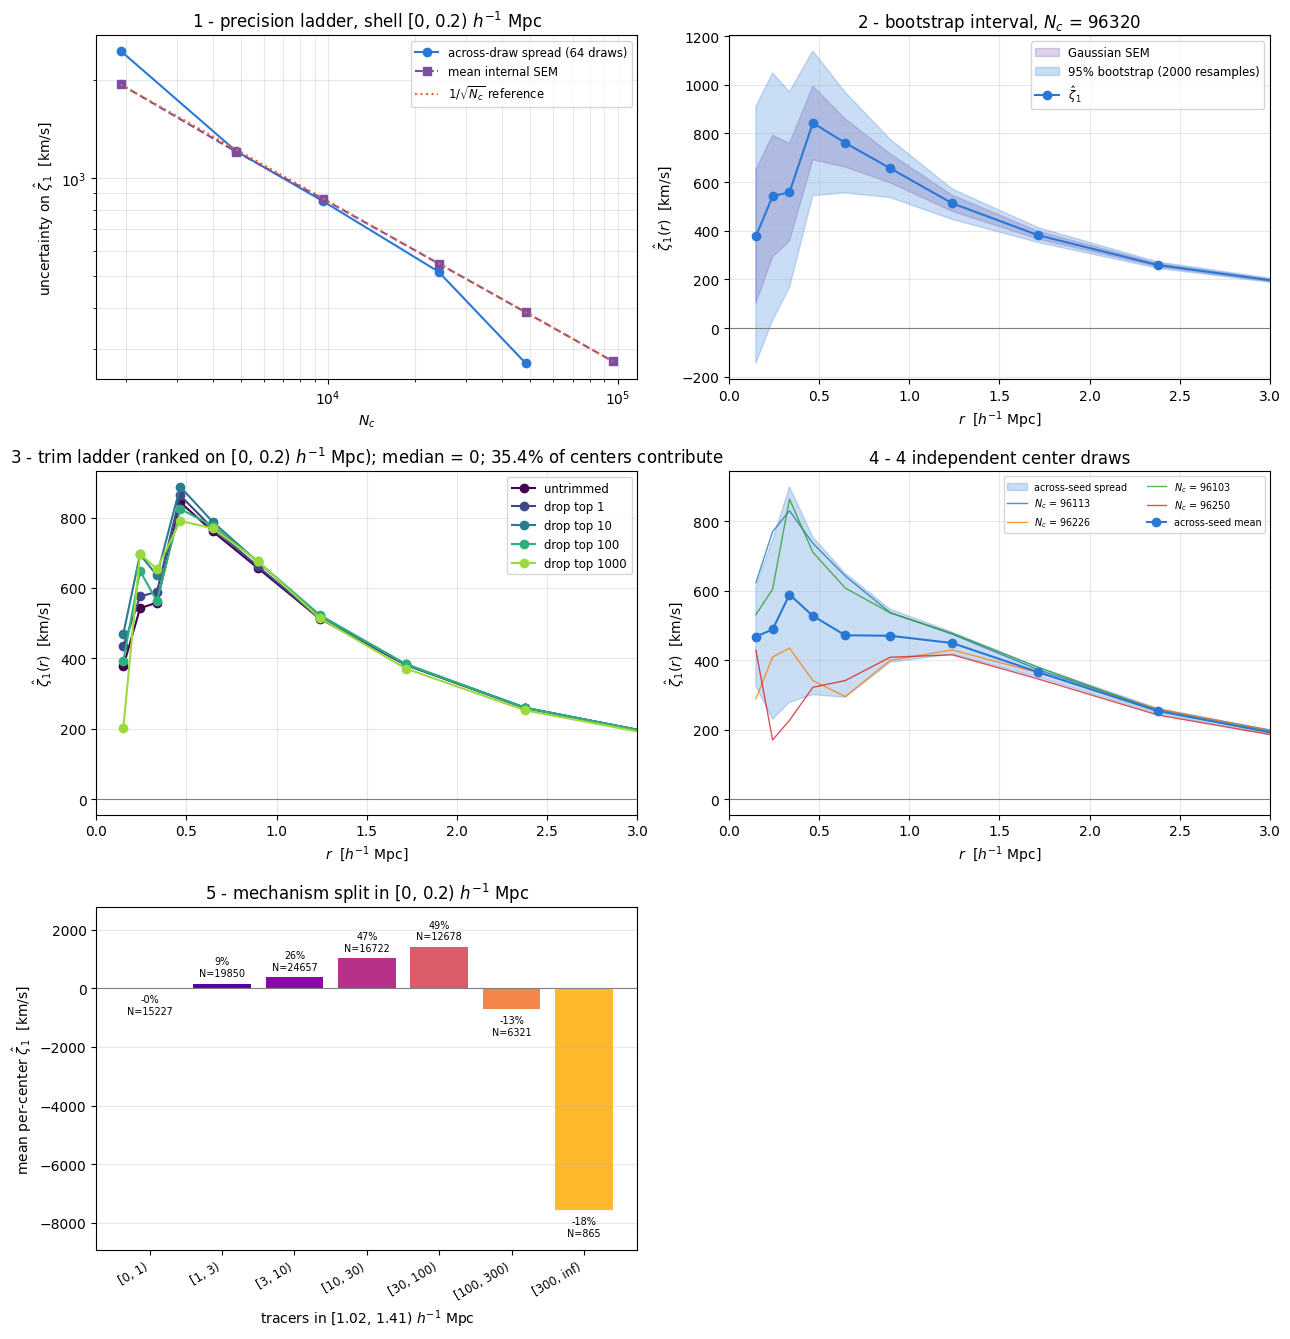

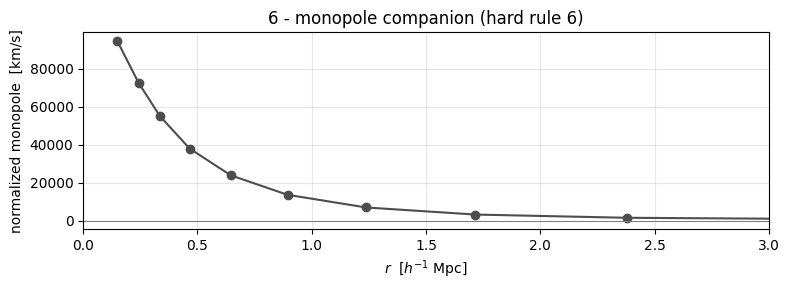

In [29]:
# DipoleFigures(dipole, monopole): .dipole is the 5-panel sheet (tests 1-5),
# .monopole is the separate companion figure (hard rule 6).
figures_robust = make_robustness_figure(
    rbcfg, stack, ladder, interval, trim, repeats, crowding
)

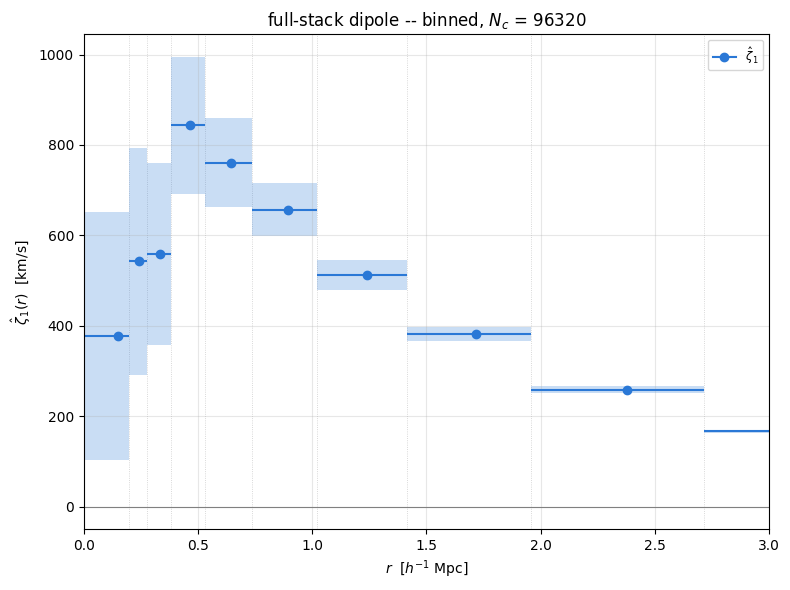

In [30]:
figures_robust_binned = make_robustness_figure(
    rbcfg, stack, ladder, interval, trim, repeats, crowding, binned=True
)

## C.8 — The verdict

Two questions came into this section. Resolving the inner region separates them, and they get
opposite answers.

### 1. §A and §B's negative innermost bin is noise

Merged back to one bin for a like-for-like comparison (`merge_shells`, C.3), §C reads
**725.1 ± 161.8 km/s** over `[0, 0.532)` against **−730.2** over `[0, 0.5)` on §A and §B's
shared 3556 centres. That is not a disagreement. Scaled to 3556 centres, §C's merged SEM gives
an expected 1σ wander of **~840 km/s** in that bin (161.8 × √(96320/3556)), so the two sit
~1.7σ apart, before the 1.3–1.6× widening C.5 finds for overlapping shells. §A's own null band
says the same thing from the other side: −730 is 1.4 null spreads from zero. A number whose
sampling distribution is wider than the number itself cannot support any reading, least of all
a sign flip. (The same held on the earlier r_max = 40 ladder, where §A's lumped `[0, 2)` read
80.4 and 301.9 on two centre sets against §C's 456.0 ± 24.6 merged over `[0, 1.959)`.)

### 2. But there *is* a turnover near zero — it was invisible in the lumped bin

The resolved ladder rises inward to a peak and then falls back:

| r (h⁻¹ Mpc) | 8.6 | 3.2 | 1.7 | 1.2 | 0.88 | 0.63 | **0.46** | 0.33 | 0.24 | 0.10 |
|---|---|---|---|---|---|---|---|---|---|---|
| ζ̂₁ | 49 | 167 | 381 | 513 | 657 | 761 | **843** | 558 | 542 | 377 |

**ζ̂₁ peaks at r ≈ 0.46 h⁻¹ Mpc and declines inside it.** §A's default ladder now reaches far
enough in to hint at a turnover too (its observer-frame curve peaks at 704 km/s at r ≈ 0.9 and
falls to 370 at r ≈ 0.6), but on 3556 centres those shells are inside the resolution floor and
within a few null spreads of zero, so only §C's run resolves it. The earlier lumped `[0, 2)` bin
could not show it at all: it is volume-dominated by its outer part. The turnover appears in **all
four independent centre draws** and at **every trim depth**, so its existence is not an outlier
artifact.

Its *depth*, though, is not measured. The inner three bins carry across-seed spreads of
143–310 km/s on values of 377–558, and the `[0, 0.2)` bootstrap interval is
**[−145, 911]** — consistent with the peak value and with zero alike. The honest statement is:
**there is a turnover inside ~0.5 h⁻¹ Mpc; how far down it goes needs more centres.** Test 1
says how many: the scatter is clean 1/√N_c over a 50× range, so 10× more centres would put the
`[0, 0.2)` bin at ±87 km/s.

### 3. The mechanism is virial cancellation, and the split now shows it

Grouping centres by their environment at 1.02–1.41 h⁻¹ Mpc — measured *away* from the shell
under test, so the split is not circular — and reading their contribution to `[0, 0.2)`:

| neighbours | [0,1) | [1,3) | [3,10) | [10,30) | [30,100) | [100,300) | [300,∞) |
|---|---|---|---|---|---|---|---|
| N_c | 15227 | 19850 | 24657 | 16722 | 12678 | 6321 | 865 |
| mean contribution | −2 | 161 | 376 | 1020 | **1412** | **−720** | **−7573** |

The contribution rises with density, peaks, and then **goes negative** for the most crowded
centres. Those are centres sitting deep inside massive halos, and at r < 0.2 h⁻¹ Mpc their
neighbours are not infalling onto them — they are orbiting, with a near/far asymmetry that
carries the opposite sign. That is the virial cancellation, isolated to the centres and the
scales where it should operate.

**This corrects the reading the lumped bin supported.** Over `[0, 2)` the crowded centres are
the *largest positive* contributors, because that bin is dominated by the infall region outside
the virial radius. Both statements are true of their own bin; only the resolved one answers the
question that was actually asked.

### What this leaves open

**The SEM is optimistic.** Across-seed spread runs above test 1's prediction (468 ± 143 against
a predicted ±274 in the innermost bin) — centres this dense share tracers, exactly the caveat
`center_standard_error`'s docstring raises. Note also that at the *smallest* rung the empirical
spread sits **above** the internal SEM (2460 against 1942): with few centres the heavy tail is
not sampled and the Gaussian error bar under-reports.

**The centre sphere matters.** §C's centres live within `130 − 10 = 120` h⁻¹ Mpc of the
observer; §A's and §B's within `130 − (64 + 15.5) = 50.5`. On the shells they roughly share
(r ≈ 2–3.5), §A's amplitudes run ~35% above §C's, by more than either error bar. Same tracers, same estimator — in a
*constrained* realization the inner volume is not a generic one, so ζ̂₁ may genuinely depend on
how far out centres are allowed to sit. It is the same effect that put the old §A (centres
within 90) ~10% off §B in the resolved shells, and the reason §A and §B now share one set.
Separate question; not diagnosed here.

**Below 0.2 h⁻¹ Mpc is the softening.** The `[0, 0.2)` bin is the innermost thing this
simulation can be asked about at all, and inside it the gravity that produced these velocities
was smoothed. Read it as a boundary marker, not as r → 0.

### The recipe, restated

1. **Resolve before you interpret.** A wide bin plotted at its midpoint is not a measurement of
   its inner edge — it is volume-weighted toward its outer one. If the question is "what
   happens as r → 0", the binning has to be able to answer it.
2. **Buy precision where it is cheap.** Shrink `max_radius` if the feature is at small r — the
   query ball scales as r³ *and* the core cut keeps far more centres (80% here against ~7% in
   §A/§B), so the same runtime buys an order of magnitude more of them.
3. **Bootstrap the bin.** Read an interval that did not assume normality, not a marker.
4. **Trim the top 0.1–0.5%.** If the *shape* survives, the shape is real even when the
   amplitude is not.
5. **Redraw the centres.** The only check that includes the selection, and the only one that
   catches a correlated-sample error bar.
6. **Split on the variable the explanation names — measured somewhere else.** A mechanism
   predicts an ordering; a fluctuation predicts nothing. Measuring the splitting variable in the
   same shell you are testing makes the answer partly self-fulfilling.

# §D — What each frame costs: the three ratios

§A and §B measured the same box three ways, on the same binning, with the same
estimator and — since A.2 — on the same centres. The three differ only in what the shell expansion is oriented on and where the
tracers sit:

| curve | axis ẑ | weight | what it is |
|---|---|---|---|
| **3D** | `v̂` | `\|v\|` | the observer-free velocity frame — everything the simulation knows |
| **obs** | `sign(u)·n̂_V` | `\|u\|` | one line-of-sight component, i.e. what a survey actually measures |
| **z** | `sign(u)·n̂_V` | `\|u\|` | the same, with the tracer field displaced into redshift space |

Each row down that table throws information away. This section prices each loss as one
number — the shell-averaged ratio — using `dvcorr.pipeline.frame_ratios`. Because all three
ratios come from the same three curves, `(3D/obs) × (obs/z) = 3D/z` holds bin by bin, so the
figure cannot quietly disagree with itself.

**A ratio is not a correction factor.** `obs` is a *projection* of `3D`, so it carries a
geometric factor before any physics — and it is a **different** factor for the dipole than
for the monopole. For the dipole, isotropy alone predicts exactly **3**: the observer frame
projects twice, once in the scalar (|u| = |v|·|cos θ|) and once in the axis, keeping
⟨µ²⟩ = 1/3 of the velocity frame's dipole at any observer distance. The familiar
⟨|u|⟩/⟨|v|⟩ = 1/2 — §A.7 measured 0.5 on this box — is the **monopole** factor, and reading
its 2 as the dipole's baseline understates the projection loss by 3/2. So a `3D/obs` dipole
near 3 is that geometry, not a signal. What is worth reading is the ratio's **run with scale
relative to 3** — flat means the loss is a constant a model can divide out, sloped means it
is scale-dependent and cannot be.

**Some shells have no ratio.** The redshift-space dipole changes sign in this box (§B: negative
out to r ≈ 14, positive from r ≈ 19), so it passes through zero, and the bins nearest the crossing
are poles whose value is set by where the bin edges happened to fall. Those shells are drawn
with **open markers** and excluded from the mean; `format_frame_ratio_table` prints the
unguarded mean alongside so the guard's effect is visible rather than assumed.


## D.1 — The three ratios, shell by shell


In [31]:
from dvcorr.pipeline.frame_ratios import (
    FrameRatioConfig,
    frame_curve,
    frame_ratio,
    frame_ratios,
    format_frame_ratio_table,
    make_frame_ratio_figure,
)

# Ordered most -> least information, so each pair reads as "what the lower frame
# loses": 3D/obs is the projection cost, obs/z the redshift-space cost, 3D/z both.
frames = (
    frame_curve("3D",  cfg.shells.shell_edges,   comparison.vel,         centers.n_centers),
    frame_curve("obs", cfg.shells.shell_edges,   comparison.obs,         centers.n_centers),
    frame_curve("z",   rcfg.shells.shell_edges,  rs_comparison.redshift, rs_centers.n_centers),
)

# The shells inside resolved_min_radius are below the interparticle spacing
# (sec.A's config cell) and the noisiest by far: plotted, never averaged.
frcfg = FrameRatioConfig(resolved_min_radius=resolved_min_radius)
ratios = frame_ratios(frcfg, frames)

print(format_frame_ratio_table(ratios))
print("chain identity  (3D/obs) x (obs/z) - (3D/z)  max |residual| :",
      f"{np.nanmax(np.abs(ratios[0].ratio * ratios[2].ratio - ratios[1].ratio)):.2e}")


3D/obs   mean = 4.147 over 10/15 shells   (unguarded mean 4.024)
     r_eff       ratio    monopole   used
      0.38      -0.731       2.039   NO (denominator ~ 0 or unresolved)
      0.62       5.473       2.031   NO (denominator ~ 0 or unresolved)
      0.87       3.416       2.035   NO (denominator ~ 0 or unresolved)
      1.23       3.050       2.020   NO (denominator ~ 0 or unresolved)
      1.74       2.801       1.982   NO (denominator ~ 0 or unresolved)
      2.46       2.382       1.997   yes
      3.48       2.637       2.083   yes
      4.92       3.334       2.182   yes
      6.96       3.395       2.194   yes
      9.84       3.323       2.189   yes
     13.92       3.738       2.182   yes
     19.69       4.951       2.201   yes
     27.84       5.529       2.203   yes
     39.38       8.597       2.205   yes
     55.69       3.583       2.210   yes

3D/z   mean = -0.964 over 8/15 shells   (unguarded mean 7.597)
             SIGN CHANGE -- that mean is a cancellation; th

## D.2 — The like-for-like control, now an identity

With one centre set (A.2), §A's observer frame and §B's real space are the same estimator on
the same centres and the same tracers, so they must agree to the last bit, and the
cross-section `obs/z` must equal §B's own same-centre `real/z`. The cell checks both rather
than assuming them.

This used to be a measurement. When §A ran on its own larger draw, `§A obs / §B real` read
**0.903 ± 0.067** over the resolved shells: a ~10% offset between two sub-volumes of a
constrained box, carried silently by every cross-section ratio. With that gone, the floor on
§D's ratios is the centres' own sampling noise — the SEM bands, read with §C.5's 1.3–1.6×
correction for overlapping shells.

In [32]:
same_centers = frame_ratio(
    frcfg,
    frame_curve("real", rcfg.shells.shell_edges, rs_comparison.real, rs_centers.n_centers),
    frame_curve("z", rcfg.shells.shell_edges, rs_comparison.redshift, rs_centers.n_centers),
)
print("sec.A obs == sec.B real on every shell:",
      np.array_equal(comparison.obs.zeta_hat, rs_comparison.real.zeta_hat),
      f"  (max |difference| {np.max(np.abs(comparison.obs.zeta_hat - rs_comparison.real.zeta_hat)):.1e} km/s)")
print("monopoles too                         :",
      np.array_equal(comparison.obs.monopole_norm, rs_comparison.real.monopole_norm))
print()
print(f"obs/z  (sec.A obs / sec.B z)  : mean = {ratios[2].mean_ratio:6.3f}"
      f"  over {ratios[2].n_used}/{ratios[2].n_shells} shells")
print(f"real/z (sec.B real / sec.B z) : mean = {same_centers.mean_ratio:6.3f}"
      f"  over {same_centers.n_used}/{same_centers.n_shells} shells")

sec.A obs == sec.B real on every shell: True   (max |difference| 0.0e+00 km/s)
monopoles too                         : True

obs/z  (sec.A obs / sec.B z)  : mean = -0.894  over 8/15 shells
real/z (sec.B real / sec.B z) : mean = -0.894  over 8/15 shells


## D.3 — The figure

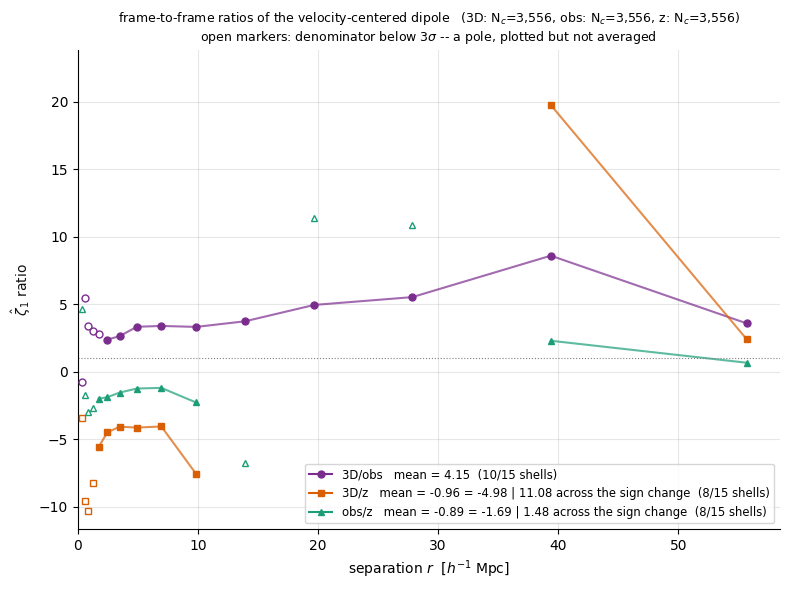

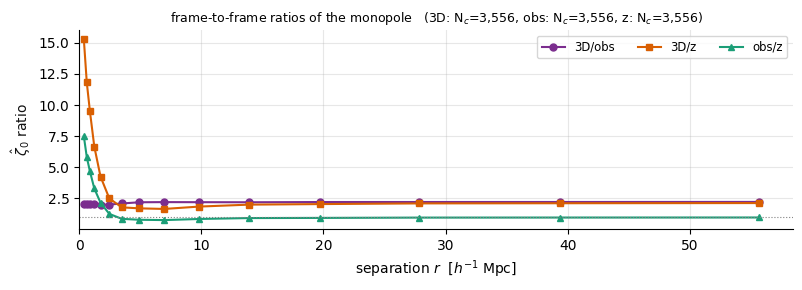

In [33]:
# DipoleFigures(dipole, monopole) -- two separate figures (hard rule 6).
figures_ratios = make_frame_ratio_figure(frcfg, frames, ratios)

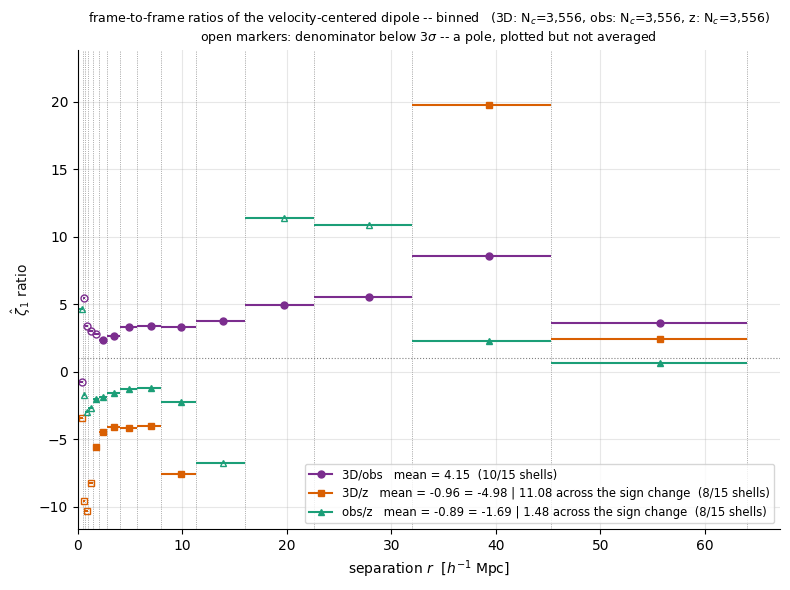

In [34]:
figures_ratios_binned = make_frame_ratio_figure(frcfg, frames, ratios, binned=True)

## D.4 — Reading it

**`3D/obs` = 4.15 over the resolved shells, against an isotropic baseline of 3, and it is not
flat.** For the *dipole* an isotropic velocity field predicts exactly **3**, not 2:
the observer frame projects twice — once in the scalar (|u| = |v|·|cos θ|), once in the axis
— and so retains ⟨µ²⟩ = 1/3 of the velocity frame's dipole, at any observer distance and
with no distant-observer limit taken anywhere (derivation in
`dvcorr.estimators.velocity_frame_dipole`; pinned on one shared centre set by
`tests/test_velocity_frame_dipole.py::test_isotropic_frame_ratio_is_three`). The factor **2**
is the *monopole's*, and the monopole panel sits near it: 2.02–2.04 in the inner shells, rising
to ~2.2 from r ≈ 5 outward. That matches §A.7's ⟨|v|⟩/⟨|u|⟩ = 2.20: this centre set, all within
50.5 h⁻¹ Mpc of the observer, is ~10% less radial than isotropy would make it.

Read against 3, the dipole ratio starts **below** its baseline: **2.38** at r ≈ 2.5 (21% low)
and 2.64 at r ≈ 3.5. It crosses 3 near r ≈ 4, stays within ~25% of it out to r ≈ 14
(3.32–3.74), and then runs well past it: **4.95** at r ≈ 20, **5.53** at 28 and **8.60** at 39,
before dropping back to **3.58** in the outermost shell at 56. The shell mean of 4.15 is set
mostly by those outer shells, and two cautions apply to them. First, the observer-frame dipole
there is only 4–20 km/s, so a small absolute offset moves the ratio a lot; the 8.6 → 3.6 swing
between the last two shells is that sensitivity. Second, finite-distance leakage is no longer
small: a 64 h⁻¹ Mpc shell around a centre within 50.5 h⁻¹ Mpc of the observer *contains the
observer*, so n̂_V is nowhere near common across it. The weight ratio is nearly flat, so the
run is not the weight. The other candidates are the angular incompleteness of the carve and the
plain fact that a *constrained* realization is not statistically isotropic about this particular
observer. **What survives: the ratio is not a constant and cannot be divided out as one.**
Within r ≈ 14 the departure is ±25% about 3; the default ladder's reach to 64 shows it growing
well beyond that.

**`obs/z` is two regimes, and the mean of the two describes neither.** Inside the RSD crossing
(shells r ≈ 1.7–10) the branch mean is **−1.69**: redshift space does not merely damp the
dipole, it *reverses* it. The three shells at r ≈ 14–28 sit on the crossing, where the
redshift-space dipole is within its own noise of zero (−5.5, 1.8 and 1.0 km/s), and are
excluded. Outside, the branch mean is **+1.48**, from only two shells: 2.30 at r ≈ 39 and
**0.67** at 56. Below 1 means redshift space gives the *larger* dipole. That is the Kaiser
enhancement, appearing only in the outermost shell, where fingers-of-God have stopped
dominating. The single averaged −0.89 is the mean of a −1.7 branch and a +1.5 branch, an
artifact of where the bins fell.

**`3D/z` is the product of the two, and nothing more:** the chain residual
`(3D/obs)·(obs/z) − (3D/z)` is 7.1e-15, i.e. floating-point. Its branches, −4.98 and +11.08,
are the projection cost and the redshift-space cost compounded.

**How precisely can any of this be read?** All three curves are now measured on one centre
set (A.2), so no ratio here carries a centre-draw offset: D.2 confirms §A's observer frame
*is* §B's real space, and the cross-section `obs/z` equals the same-centre `real/z` (−0.894
both). Under the old two-draw setup that control read 0.903 ± 0.067 — a ~10% systematic every
cross-section ratio silently inherited. What remains is the centres' own sampling noise: the
SEM bands on the curves, widened by §C.5's 1.3–1.6× for overlapping shells. Against that, the
sign structure of `obs/z` and `3D/z` is an order of magnitude larger than the noise, and the
regime split is real; the shell-to-shell wiggle in `3D/obs`, and the third decimal of any
mean here, are not.

**What is deliberately not averaged.** The four shells inside `resolved_min_radius` = 1.41 h⁻¹ Mpc
(below the interparticle spacing, and the noisiest by far). For `3D/obs`, also `[1.41, 2)`,
where the observer-frame dipole is under 3 of its own SEMs. For the two `z` ratios, the three
shells at r ≈ 14–28 on the redshift-space zero crossing, where `3D/z` reads −25 to 60 and
`obs/z` −6.7 to 11, values set by the bin edges rather than by the box. All are drawn with open
markers, and the connecting line breaks across them. Because all three curves share their
centres, the monopole panel is a clean occupancy comparison too: `obs/z` there (0.75–0.96
beyond r ≈ 3) is redshift space's shell occupancy relative to real space's, on identical
centres and identical weights.
